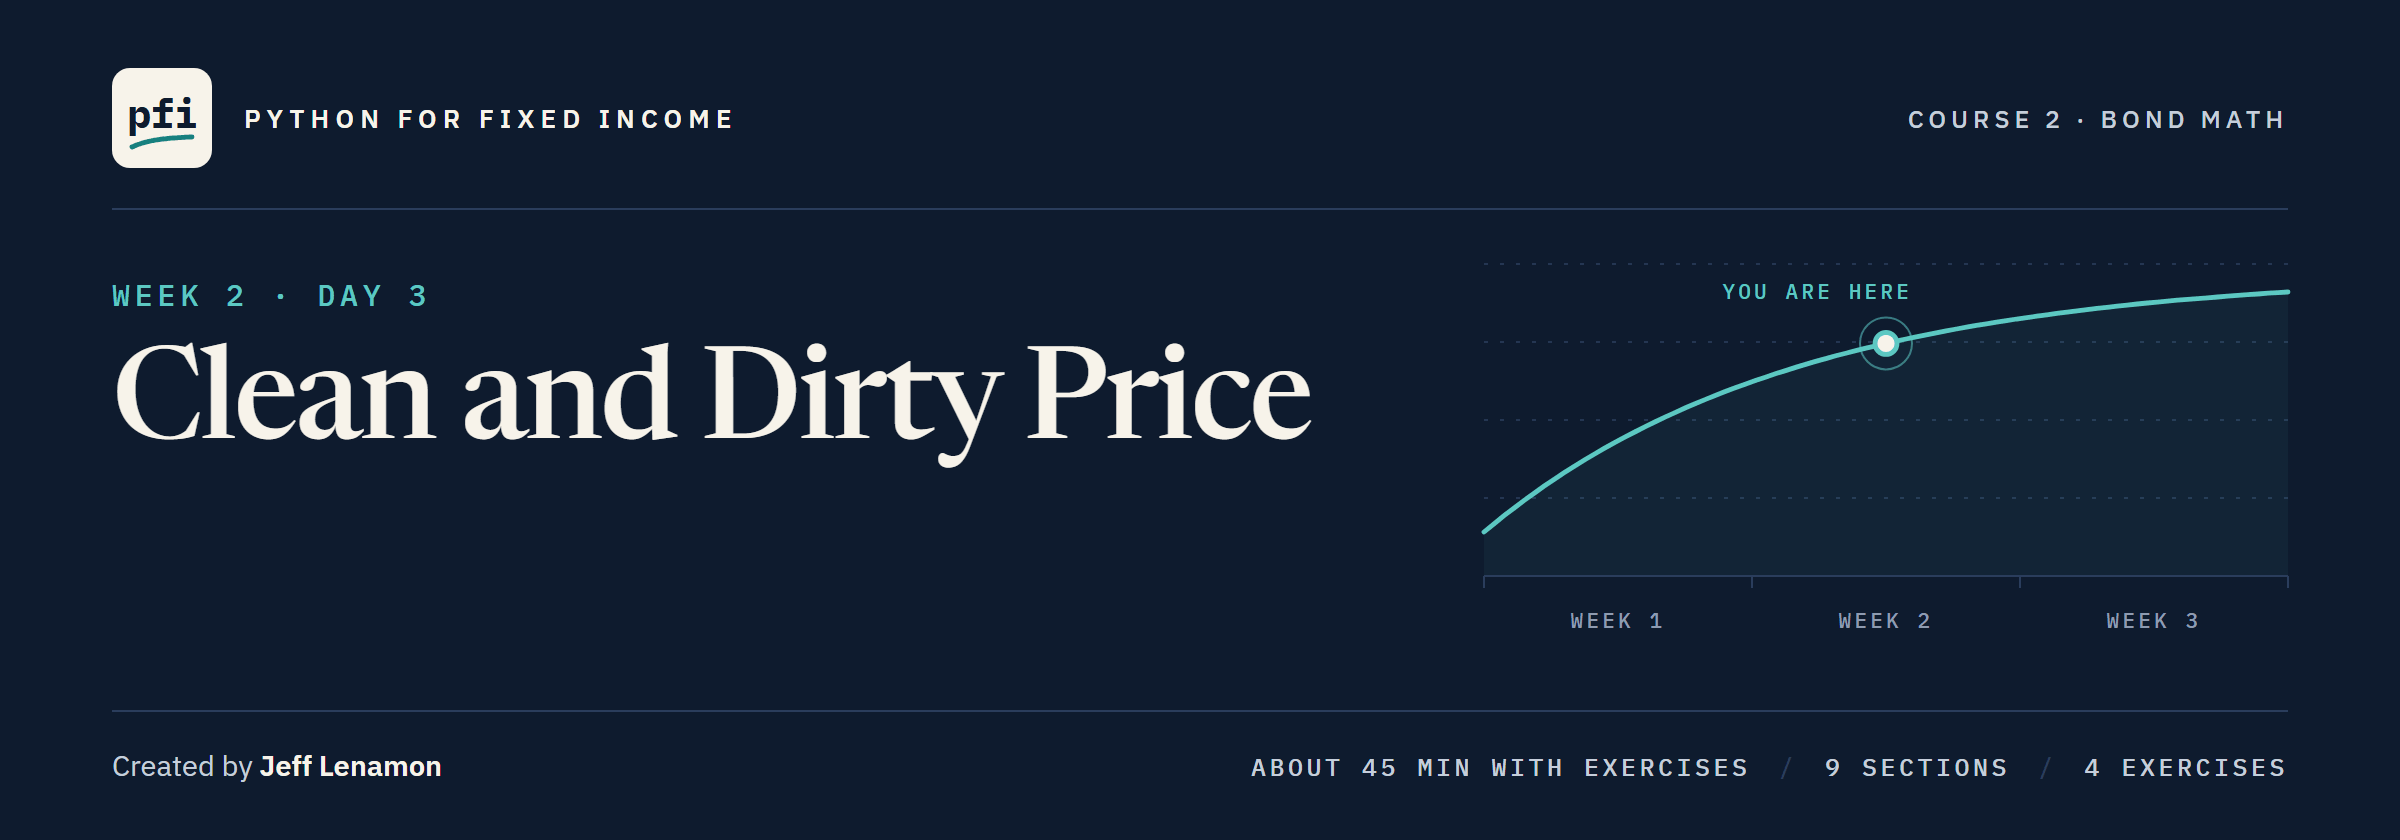

# Clean and Dirty Price

Week 2, Day 3. Price a bond between coupons: the quote, the invoice, and a price and a yield for any settlement date, tied to Excel's `PRICE` and `YIELD`.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week2/day3/08_clean_and_dirty_price.ipynb)

### The Desk Lead's Note

> We buy 1,000,000 of Quorvane Energy at its issue yield, 5.40 percent, settling Monday 30 November. Tell me the quote and the cash that leaves the account. Then give `bondmath` a price for any settlement date and a yield from any quote, both tied to Excel. Last, September's blotter shows principal only: put the accrued back on all 374 trades and tell me what the cash really was.

The issuers are invented; every statement describes the data.

**Notebook 02 priced on a coupon date; today the next coupon is four months away.**

### Today's Work Folder

Q. Where does today's work happen?

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module, its tests, and its Git history
# as notebook 07 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(8)

Work folder pfi_course2_08_k4w7q2xr: 4 data files, the module as notebook 07 left it, 7 commits, tagged week1


### The Tests Pass Before We Start

In [2]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..................                                                       [100%]
18 passed in 0.50s



### Imports and the Four Bonds

Q. Which bonds, and what does Excel say about them on 30 November?

In [3]:
import importlib
from datetime import date, timedelta

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])
import bondmath

In [4]:
# the four week 1 bonds, settled on 30 November 2026 at the yields they were issued at
bonds = pd.DataFrame({
    'cusip': ['99001BZA7', '99002CZA4', '99003DZA1', '99004EZA8'],
    'issuer': ['Quorvane Energy', 'Dunmarrow Rail', 'Pellwick Paper', 'Halvering Foods'],
    'coupon_pct': [5.25, 6.125, 4.75, 7.5],
    'maturity': [date(2031, 9, 30), date(2033, 9, 30), date(2029, 9, 30), date(2036, 9, 30)],
    'yield_pct': [5.4, 6.125, 4.6, 7.7],
})
settlement = date(2026, 11, 30)
quorvane_maturity = date(2031, 9, 30)
bonds

,cusip,issuer,coupon_pct,maturity,yield_pct
0,99001BZA7,Quorvane Energy,5.250,2031-09-30,5.400
1,99002CZA4,Dunmarrow Rail,6.125,2033-09-30,6.125
2,99003DZA1,Pellwick Paper,4.750,2029-09-30,4.600
3,99004EZA8,Halvering Foods,7.500,2036-09-30,7.700


In [5]:
# Excel's answers: the week2 rows are these bonds and four more, settled 30 November
reference = pd.read_csv('bondmath_excel_reference.csv')
week2 = reference[reference['group'] == 'week2'].set_index('case_id')
print(len(reference), 'reference rows,', len(week2), 'of them in week2')

306 reference rows, 8 of them in week2


**The module starts the day as notebook 07 left it, with 18 tests passing.**

## Your Route Through Day 3

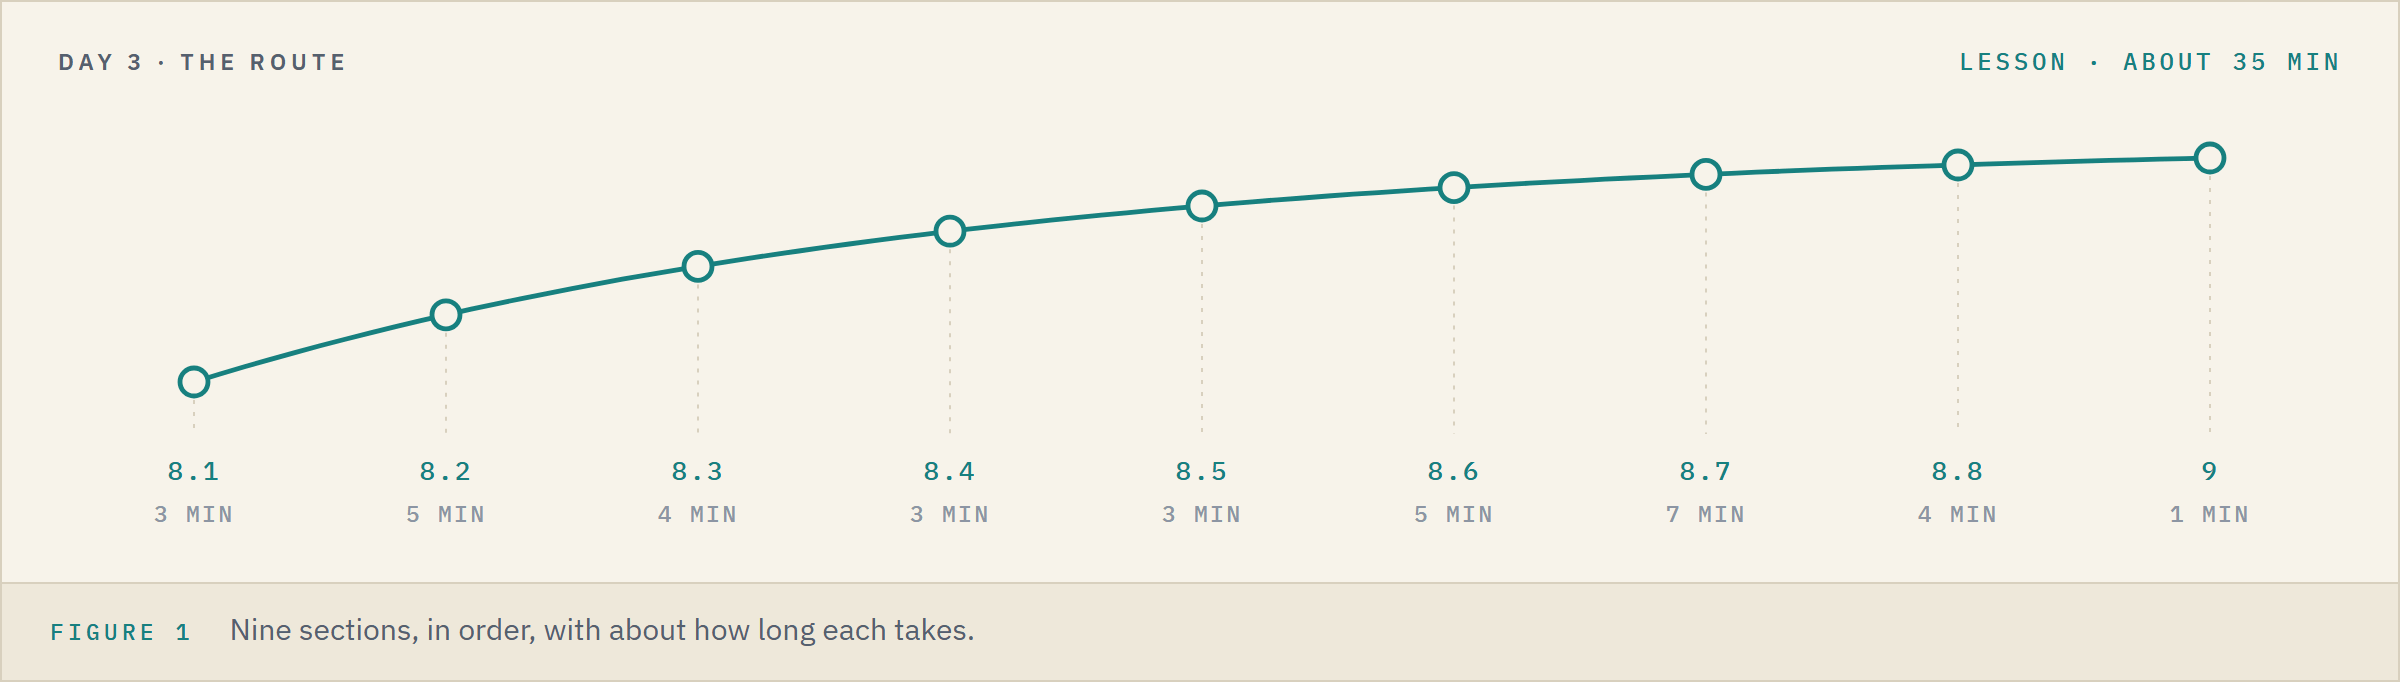

<table align="left">
<tr><th align="left"></th><th align="left">Section</th><th align="left">About</th></tr>
<tr><td align="left">8.1</td><td align="left">The Quote and the Invoice</td><td align="left">3 min</td></tr>
<tr><td align="left">8.2</td><td align="left">Discounting From Settlement, <code>w = DSC / E</code></td><td align="left">5 min</td></tr>
<tr><td align="left">8.3</td><td align="left"><code>price</code> and <code>dirty_price</code></td><td align="left">4 min</td></tr>
<tr><td align="left">8.4</td><td align="left">On a Coupon Date It Equals Notebook 02</td><td align="left">3 min</td></tr>
<tr><td align="left">8.5</td><td align="left">The Final Coupon Period</td><td align="left">3 min</td></tr>
<tr><td align="left">8.6</td><td align="left">Undo a Commit, Keep the History</td><td align="left">5 min</td></tr>
<tr><td align="left">8.7</td><td align="left"><code>yield_to_maturity</code></td><td align="left">7 min</td></tr>
<tr><td align="left">8.8</td><td align="left">The September Blotter's Invoices</td><td align="left">4 min</td></tr>
<tr><td align="left">9</td><td align="left">Bring It Home</td><td align="left">1 min</td></tr>
</table>
<br clear="left">

**Time.** About 35 minutes for the lesson, then about 12 for the four exercises.

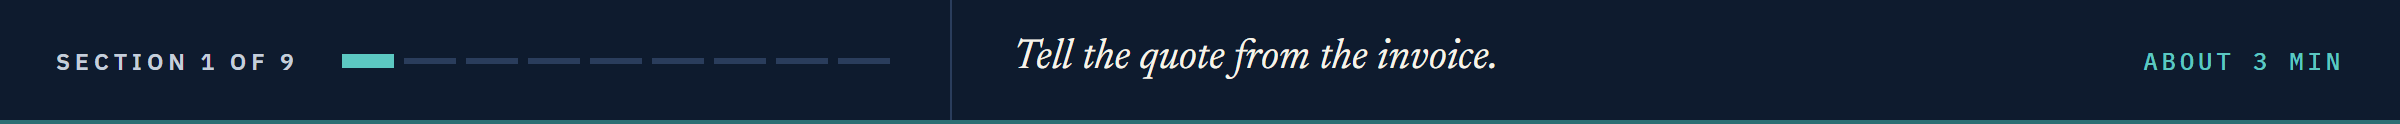

## 8.1 The Quote and the Invoice

### What Notebooks 02 and 07 Already Know

The market quotes the **clean** price; the buyer pays the **dirty** price, clean plus accrued (notebook 02's terms).
The **invoice** is the cash that settles the trade: the dirty price applied to the face.

Q. What did notebook 02 price Quorvane at on 30 September, and what has it accrued by 30 November?

In [6]:
# notebook 02: ten whole half-years to maturity, on the issue date
issue_price = bondmath.price_from_yield(5.25, 5.40, 5)
# notebook 07: one coupon times A / E, per 100 of face
quorvane_accrued = bondmath.accrued_interest(settlement, quorvane_maturity, 5.25)
print(f'Price on 30 September: {issue_price:.6f}')
print(f'Accrued on 30 November: {quorvane_accrued}')

Price on 30 September: 99.350327
Accrued on 30 November: 0.875


**Predict 1**

Q. At the same 5.40 percent yield, what does the buyer pay per 100 on 30 November? Write down a number.

### Excel's Answer

Q. Excel's `PRICE` gives the quote. What does the buyer pay, per 100 and in dollars on 1,000,000 of face?

In [7]:
excel_clean = week2.loc['99001BZA7', 'price']
dirty = excel_clean + quorvane_accrued
print(f'Quote (clean):   {excel_clean:.6f} per 100')
print(f'Invoice (dirty): {dirty:.6f} per 100')
# :>14,.2f is Course 1's :>10.2f in 14 characters, with commas
print(f'Principal: {1_000_000 * excel_clean / 100:>14,.2f} dollars')
print(f'Accrued:   {1_000_000 * quorvane_accrued / 100:>14,.2f} dollars')
print(f'Invoice:   {1_000_000 * dirty / 100:>14,.2f} dollars')

Quote (clean):   99.361551 per 100
Invoice (dirty): 100.236551 per 100
Principal:     993,615.51 dollars
Accrued:         8,750.00 dollars
Invoice:     1,002,365.51 dollars


Not 99.350327 + 0.875 = 100.225327: the quote itself rose by 0.011224 in two months.
The ticket shows the clean price; settlement moves the dirty amount.

### Quote to Invoice

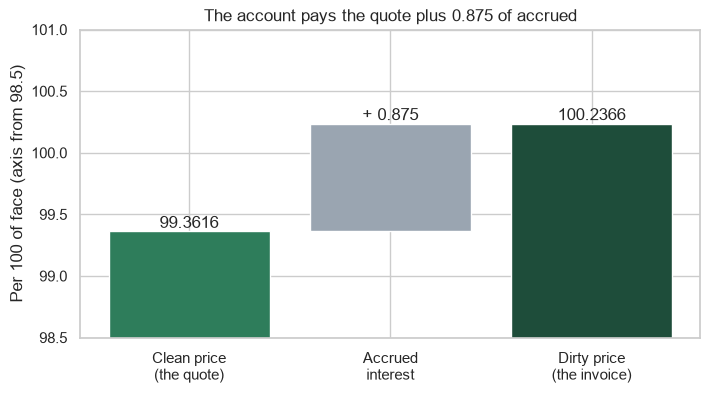

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
labels = ['Clean price\n(the quote)', 'Accrued\ninterest', 'Dirty price\n(the invoice)']
# bottom= says where each bar starts: the accrued bar sits on top of the clean price
bars = ax.bar(labels, [excel_clean, quorvane_accrued, dirty], bottom=[0, excel_clean, 0],
              color=['#2E7D5B', '#9AA5B1', '#1E4D3A'])
# labels= writes our own text on the bars
ax.bar_label(bars, labels=[f'{excel_clean:.4f}', f'+ {quorvane_accrued}', f'{dirty:.4f}'])
ax.set_ylim(98.5, 101)
ax.set_title('The account pays the quote plus 0.875 of accrued')
ax.set_ylabel('Per 100 of face (axis from 98.5)')
plt.show()

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">The quote</td><td align="left"><code>week2.loc['99001BZA7', 'price']</code></td><td align="left"><code>=PRICE(DATE(2026,11,30),DATE(2031,9,30),5.25/100,5.4/100,100,2,0)</code></td><td align="left">99.36155142589135</td></tr>
<tr><td align="left">The invoice price</td><td align="left"><code>excel_clean + quorvane_accrued</code></td><td align="left"><code>=PRICE(DATE(2026,11,30),DATE(2031,9,30),5.25/100,5.4/100,100,2,0)+100*5.25/100/2*COUPDAYBS(DATE(2026,11,30),DATE(2031,9,30),2,0)/COUPDAYS(DATE(2026,11,30),DATE(2031,9,30),2,0)</code></td><td align="left">100.23655142589135</td></tr>
</table>
<br clear="left">

**The quote is 99.361551; the account pays 1,002,365.51 dollars. Next: where the extra 0.011224 comes from.**

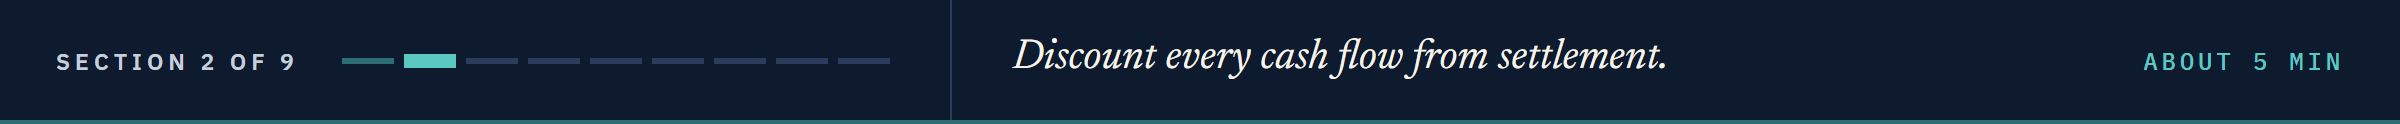

## 8.2 Discounting From Settlement, `w = DSC / E`

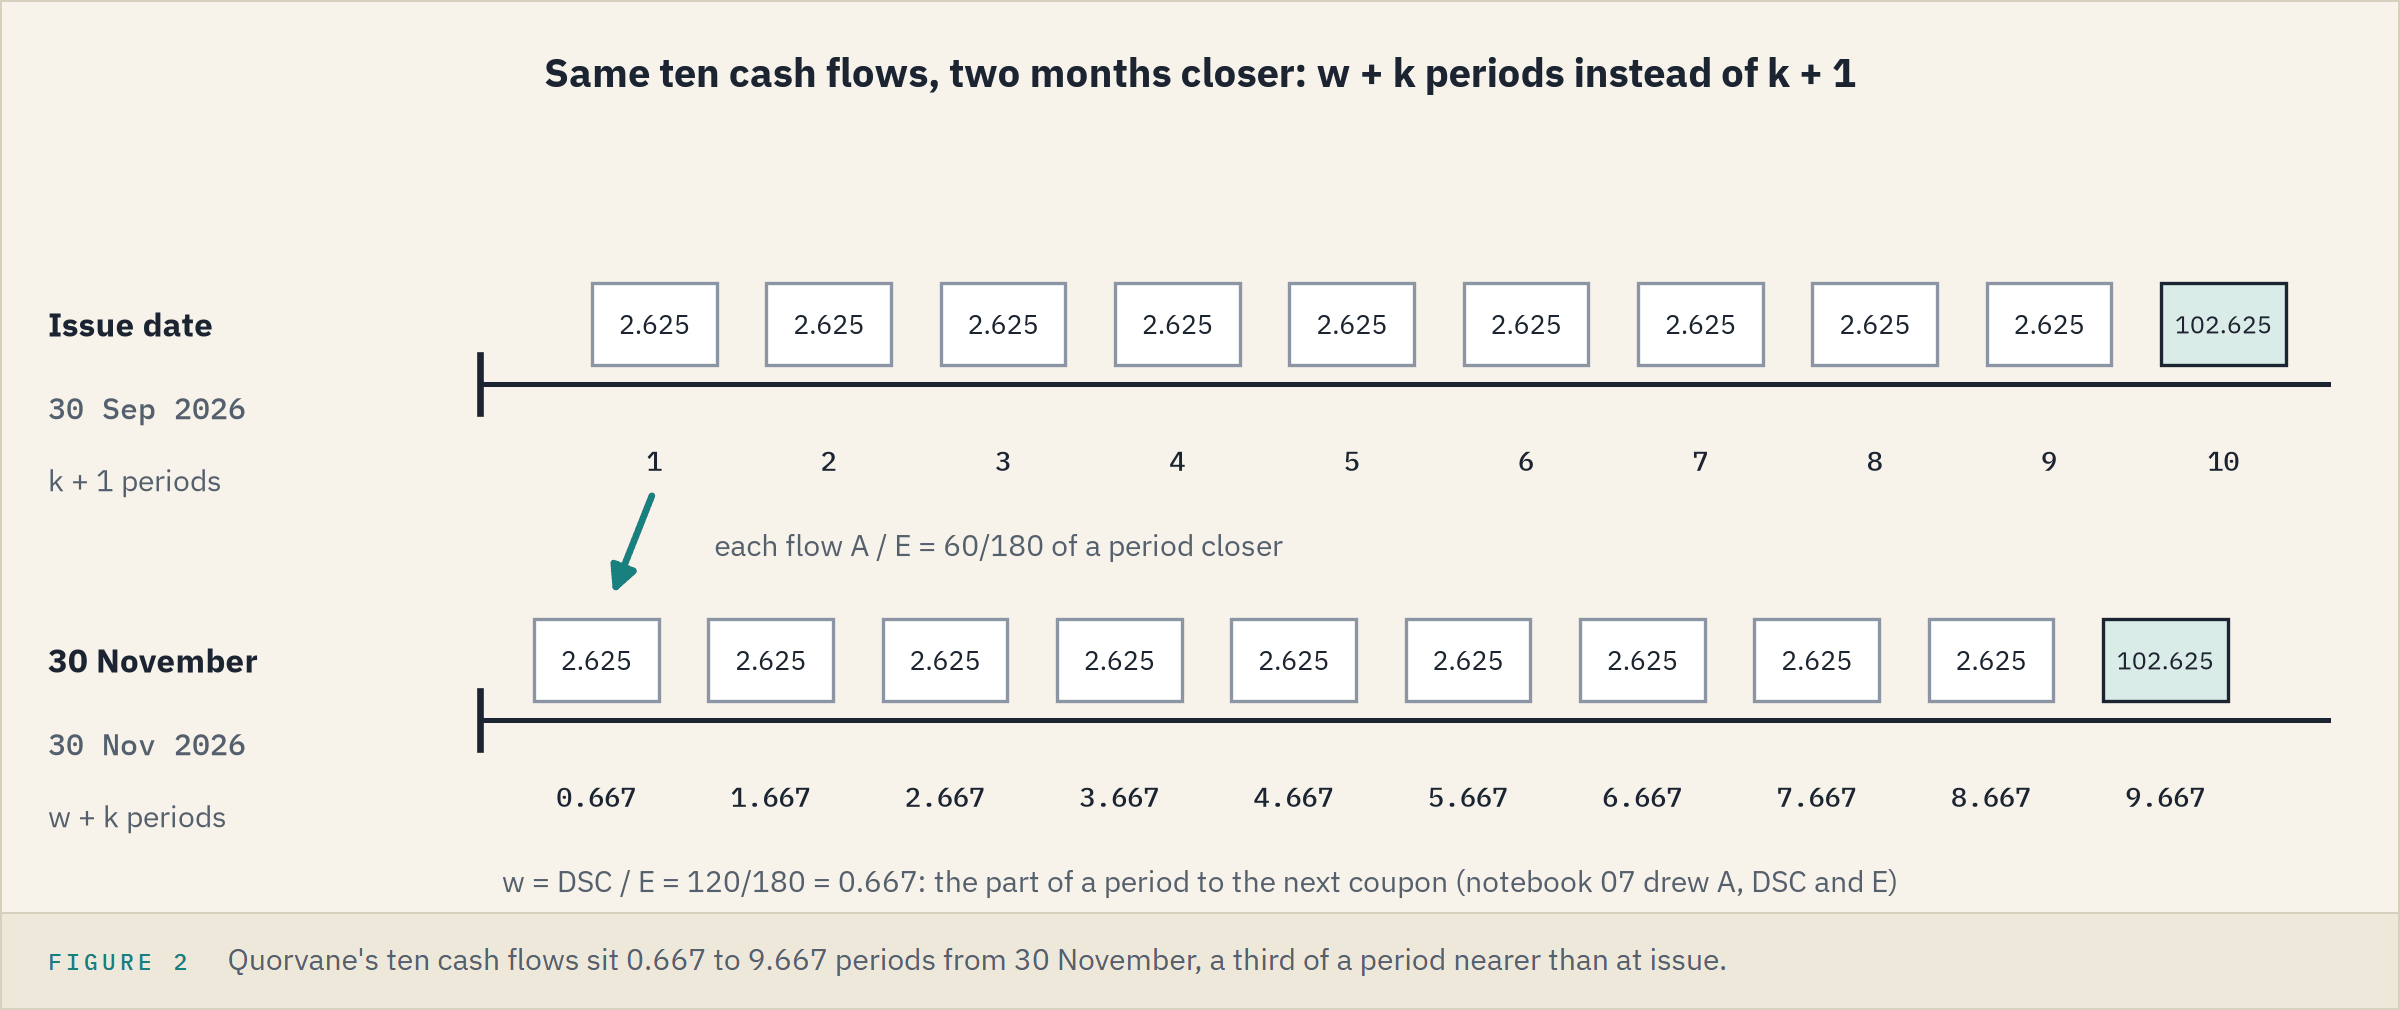

Notebook 07 split Quorvane's period into A, DSC and E.
The next coupon is now only **w = DSC / E** of a period away, and cash flow k is w + k periods away.

### A, E, DSC, and `w`

In [9]:
days_accrued, days_in_period, days_to_next = bondmath.coupon_period_days(settlement,
                                                                         quorvane_maturity)
w = days_to_next / days_in_period
print(f'A = {days_accrued}, E = {days_in_period}, DSC = {days_to_next}, w = {w:.6f}')

A = 60, E = 180, DSC = 120, w = 0.666667


### The Ten Cash Flows

Q. What is each cash flow worth, discounted over w + k periods?

In [10]:
dates = bondmath.coupon_dates(settlement, quorvane_maturity)
coupons_left = len(dates) - 1
period_yield = 5.40 / 100 / 2
rows = []
for k in range(coupons_left):
    # a coupon of 5.25 / 2, and the face with the last one
    cash_flow = 5.25 / 2 + (100 if k == coupons_left - 1 else 0)
    rows.append({'coupon_date': dates[k + 1], 'periods': w + k, 'cash_flow': cash_flow,
                 'present_value': cash_flow / (1 + period_yield) ** (w + k)})
flows = pd.DataFrame(rows)
flows.round(6)

,coupon_date,periods,cash_flow,present_value
0,2027-03-31,0.666667,2.625,2.578788
1,2027-09-30,1.666667,2.625,2.510991
2,2028-03-31,2.666667,2.625,2.444977
3,2028-09-30,3.666667,2.625,2.380698
4,2029-03-31,4.666667,2.625,2.318109
5,2029-09-30,5.666667,2.625,2.257166
6,2030-03-31,6.666667,2.625,2.197825
7,2030-09-30,7.666667,2.625,2.140043
8,2031-03-31,8.666667,2.625,2.083781
9,2031-09-30,9.666667,102.625,79.324172


### Each Coupon Is Worth Less the Further Away It Is

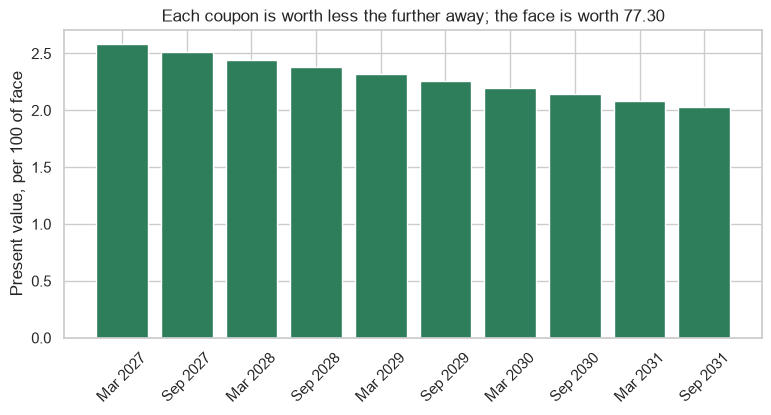

In [11]:
# each coupon of 2.625 alone, discounted; the face is written in the title
coupon_values = (5.25 / 2) / (1 + period_yield) ** flows['periods']
face_value = 100 / (1 + period_yield) ** flows['periods'].iloc[-1]
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar([d.strftime('%b %Y') for d in flows['coupon_date']], coupon_values)
ax.tick_params(axis='x', rotation=45)
ax.set_title(f'Each coupon is worth less the further away; the face is worth {face_value:.2f}')
ax.set_ylabel('Present value, per 100 of face')
plt.show()

### Add Them Up

Q. Is the sum, less the accrued, Excel's `PRICE`?

In [12]:
dirty_by_hand = flows['present_value'].sum()
clean_by_hand = dirty_by_hand - quorvane_accrued
print(f'Sum of present values: {dirty_by_hand:.10f}')
print(f'Less accrued:          {clean_by_hand:.10f}')
print(f"Excel's PRICE:         {excel_clean:.10f}")
assert abs(clean_by_hand - excel_clean) < 1e-9

Sum of present values: 100.2365514259
Less accrued:          99.3615514259
Excel's PRICE:         99.3615514259


The sum is the dirty price; take off the accrued and Excel's `PRICE` comes back to the tenth decimal.
The market discounts first and subtracts accrued second.

### Two Months Closer

Q. Why did the quote rise? Grow notebook 02's price by the A / E of a period that every flow moved closer.

In [13]:
# every cash flow is A / E of a period closer than on the issue date
shifted = issue_price * (1 + period_yield) ** (days_accrued / days_in_period)
print(f'{issue_price:.6f} grown by A / E of a period: {shifted:.6f}')

99.350327 grown by A / E of a period: 100.236551


The issue-date price, earning its yield for a third of a period, is the dirty price.
It grew by 0.886224 while only 0.875 accrued, so the quote rose by 0.011224: the answer to Predict 1.

**Excel side by side.** The price written out, in a blank sheet with k = 0 to 9 typed in A6:A15.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">A, E, coupons left in B1:B3</td><td align="left"><code>coupon_period_days</code>, <code>coupon_dates</code></td><td align="left"><code>=COUPDAYBS(DATE(2026,11,30),DATE(2031,9,30),2,0)</code>, <code>=COUPDAYS(...)</code>, <code>=COUPNUM(...)</code>, the same arguments</td><td align="left">60, 180, 10</td></tr>
<tr><td align="left">w in B4</td><td align="left"><code>w</code></td><td align="left"><code>=(B2-B1)/B2</code></td><td align="left">0.666667</td></tr>
<tr><td align="left">Each flow, B6 filled to B15</td><td align="left"><code>flows['present_value']</code></td><td align="left"><code>=IF(A6=$B$3-1,5.25/2+100,5.25/2)/(1+5.4/100/2)^($B$4+A6)</code></td><td align="left">2.578788 to 79.324172</td></tr>
<tr><td align="left">Dirty price in B16</td><td align="left"><code>dirty_by_hand</code></td><td align="left"><code>=SUM(B6:B15)</code></td><td align="left">100.23655142589136</td></tr>
<tr><td align="left">Clean price in B17</td><td align="left"><code>clean_by_hand</code></td><td align="left"><code>=B16-100*5.25/100/2*B1/B2</code></td><td align="left">99.36155142589136</td></tr>
<tr><td align="left">Dirty price, one cell</td><td align="left"><code>shifted</code></td><td align="left"><code>=-PV(5.4/100/2,COUPNUM(DATE(2026,11,30),DATE(2031,9,30),2,0),5.25/2,100)*(1+5.4/100/2)^(COUPDAYBS(DATE(2026,11,30),DATE(2031,9,30),2,0)/COUPDAYS(DATE(2026,11,30),DATE(2031,9,30),2,0))</code></td><td align="left">100.23655142589129</td></tr>
</table>
<br clear="left">

**The dirty price is the cash flows discounted from settlement; the quote is that less accrued.**

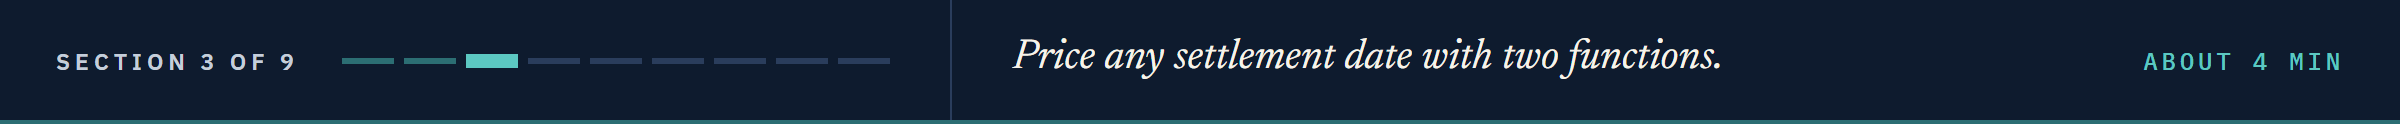

## 8.3 `price` and `dirty_price`

### Append Them, Docstring First

`price` takes `PRICE`'s arguments in Excel's order, without the redemption of 100, and returns the clean price.
Its docstring states the units (percent in, per 100 out), the convention (w + k, the final period, clean = dirty - accrued) and the Excel formula with its `/100`.
The loop is 8.2; the `if coupons_left == 1` branch is 8.5.
`dirty_price` adds `accrued_interest` back, so the two can never disagree about the accrued.

In [14]:
%%writefile -a bondmath.py


def price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
          basis: str = "30/360") -> float:
    """Clean price per 100 of face on any settlement date, as Excel's PRICE.

    Units: coupon_pct and yield_pct in percent a year; the result is a clean price per 100 of face.
    Convention: yield compounded `frequency` times a year. w = DSC / E is the part of a period left
    until the next coupon. Dirty price = sum over the N coupons left of CF_k / (1 + y/f) ** (w + k).
    In the final coupon period (N = 1) Excel uses simple interest: dirty = (100 + CF) / (1 + w x y/f).
    Clean = dirty - accrued interest.
    Excel: =PRICE(settlement, maturity, coupon_pct/100, yield_pct/100, 100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    days_accrued, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    # coupons left, the fraction of a period to the next one, the period yield, and one coupon
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    if coupons_left == 1:
        # final period: simple interest on the last coupon and the face
        dirty = (100 + coupon) / (1 + w * period_yield)
    else:
        dirty = 0.0
        for k in range(coupons_left):
            # the last cash flow also returns the face
            cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
            dirty += cash_flow / (1 + period_yield) ** (w + k)
    # the quote is clean: take off the accrued interest
    return dirty - accrued_interest(settlement, maturity, coupon_pct, frequency, basis)


def dirty_price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                basis: str = "30/360") -> float:
    """Dirty (full, invoice) price per 100 of face: the clean price plus accrued interest.

    Units and convention as price(). Excel: =PRICE(...) + the accrued formula.
    """
    # clean price plus accrued interest
    return (price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
            + accrued_interest(settlement, maturity, coupon_pct, frequency, basis))

Appending to bondmath.py


**Predict 2**

Q. Dunmarrow's coupon equals its yield, 6.125 percent, so notebook 02 priced it at 100. Its clean price on 30 November, between coupons, is:

A) exactly 100, the coupon still equals the yield
B) a little under 100
C) a little over 100

### Four Bonds Against Excel

In [15]:
importlib.reload(bondmath)
maturities, coupons, yields = bonds['maturity'], bonds['coupon_pct'], bonds['yield_pct']
prices = bonds[['issuer']].copy()
prices['clean'] = [bondmath.price(settlement, m, c, y)
                   for m, c, y in zip(maturities, coupons, yields)]
prices['excel'] = week2.loc[bonds['cusip'], 'price'].to_numpy()
prices['dirty'] = [bondmath.dirty_price(settlement, m, c, y)
                   for m, c, y in zip(maturities, coupons, yields)]
assert ((prices['clean'] - prices['excel']).abs() < 1e-6).all()
prices.round(6)

,issuer,clean,excel,dirty
0,Quorvane Energy,99.361551,99.361551,100.236551
1,Dunmarrow Rail,99.989753,99.989753,101.010586
2,Pellwick Paper,100.388247,100.388247,101.179914
3,Halvering Foods,98.622491,98.622491,99.872491


B: Dunmarrow is 99.989753.
The cash flows are discounted with compounding, while accrued grows in a straight line, so the two do not cancel between coupons; on every coupon date a par bond is 100 again.
All four clean prices are Excel's `PRICE`.

### Clean Plus Accrued

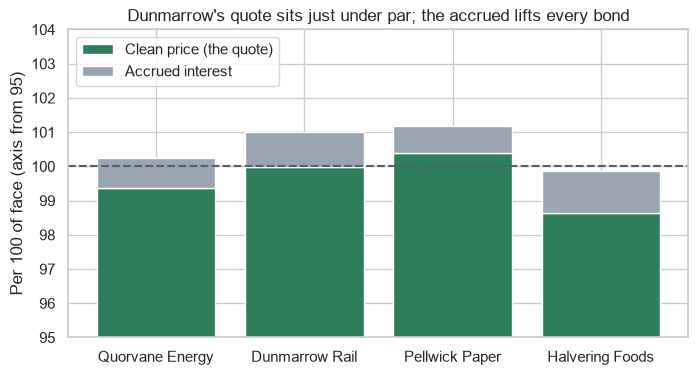

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(prices['issuer'], prices['clean'], label='Clean price (the quote)')
ax.bar(prices['issuer'], prices['dirty'] - prices['clean'], bottom=prices['clean'],
       label='Accrued interest')
ax.axhline(100, color='#52606D', linestyle='--')
ax.set_ylim(95, 104)
ax.set_title("Dunmarrow's quote sits just under par; the accrued lifts every bond")
ax.set_ylabel('Per 100 of face (axis from 95)')
ax.legend(loc='upper left')
plt.show()

### Two Tests From the Reference File

`bond_inputs(row)` (notebook 07) returns a tuple of six arguments.
A `*` before it in a call hands them over one by one: `price(*bond_inputs(row))` is `price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)`.

In [17]:
%%writefile -a test_bondmath.py


def test_price_matches_excel():
    for row in REFERENCE:
        result = bondmath.price(*bond_inputs(row))
        assert result == pytest.approx(float(row["price"]), abs=1e-6), row["case_id"]


def test_dirty_is_clean_plus_accrued():
    for row in REFERENCE:
        result = bondmath.dirty_price(*bond_inputs(row))
        # Excel's PRICE plus Excel's accrued formula
        assert result == pytest.approx(float(row["price"]) + float(row["accrued"]), abs=1e-6), row["case_id"]

Appending to test_bondmath.py


In [18]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

....................                                                     [100%]
20 passed in 0.50s



**`price` matches Excel's `PRICE`, and `dirty_price` `PRICE` plus accrued, on all 306 reference rows.**

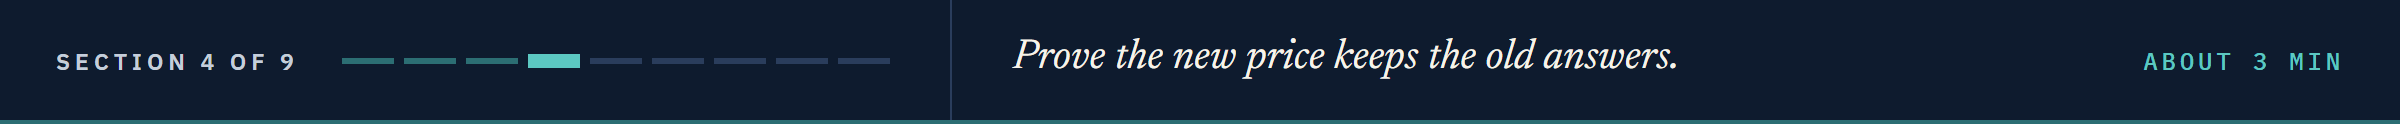

## 8.4 On a Coupon Date It Equals Notebook 02

### A Year of Settlement Dates

Q. At a steady 5.40 percent, what do the quote and the invoice do over a year?

In [19]:
# every settlement day for a year from the issue date
days = [date(2026, 9, 30) + timedelta(days=i) for i in range(366)]
clean_prices = [bondmath.price(d, quorvane_maturity, 5.25, 5.40) for d in days]
dirty_prices = [bondmath.dirty_price(d, quorvane_maturity, 5.25, 5.40) for d in days]
print(f'Dirty on 30 and 31 March 2027: {dirty_prices[181]:.6f}, {dirty_prices[182]:.6f}')

Dirty on 30 and 31 March 2027: 102.032786, 99.407786


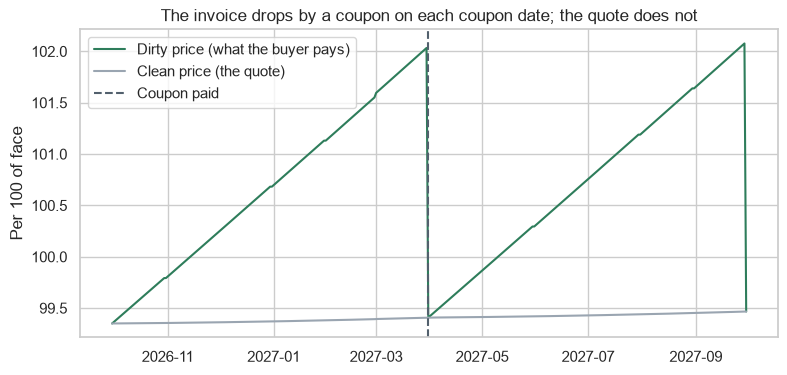

In [20]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(days, dirty_prices, label='Dirty price (what the buyer pays)')
ax.plot(days, clean_prices, label='Clean price (the quote)')
ax.axvline(date(2027, 3, 31), color='#52606D', linestyle='--', label='Coupon paid')
ax.set_title('The invoice drops by a coupon on each coupon date; the quote does not')
ax.set_ylabel('Per 100 of face')
ax.legend()
plt.show()

The dirty price falls by exactly 2.625 on 31 March: under 30/360, 30 March already counts all 180 days.
The clean price moves smoothly towards 100, so a change in the quote is a change in value, not in the calendar.
That is why the market quotes clean.

### The Issue Date

Q. On 30 September, a coupon date, does `price` give notebook 02's answer for all four bonds?

In [21]:
print(bondmath.coupon_period_days(date(2026, 9, 30), quorvane_maturity))
on_issue = [bondmath.price(date(2026, 9, 30), m, c, y)
            for m, c, y in zip(maturities, coupons, yields)]
# on the issue date every bond has a whole number of years left
from_02 = [bondmath.price_from_yield(c, y, m.year - 2026)
           for m, c, y in zip(maturities, coupons, yields)]
print(max([abs(a - b) for a, b in zip(on_issue, from_02)]))

(0, 180, 180)
0.0


A = 0 and DSC = E, so w = 1 and nothing is taken off: the same four prices.
A new function must keep the old answers.

### The Test

Q. On every reference row that settles on a coupon date, does `price` equal `price_from_yield`?

The rows are picked as notebook 02's coupon-date test picks them, and `assert coupon_date_rows` stops the test passing on an empty list.

In [22]:
%%writefile -a test_bondmath.py


def test_price_on_coupon_date_equals_week1():
    coupon_date_rows = [row for row in REFERENCE if row["coupdaybs"] == "0"]
    assert coupon_date_rows, "no coupon-date rows in the reference file"
    for row in coupon_date_rows:
        settlement, maturity, coupon_pct, yield_pct, frequency, basis = bond_inputs(row)
        # on a coupon date the bond has a whole number of periods left
        years = int(row["coupnum"]) / frequency
        week1_price = bondmath.price_from_yield(coupon_pct, yield_pct, years, frequency)
        assert bondmath.price(settlement, maturity, coupon_pct, yield_pct, frequency, basis) == pytest.approx(
            week1_price, abs=1e-9), row["case_id"]

Appending to test_bondmath.py


**The new function keeps every old answer, and the quote does not jump on coupon day.**

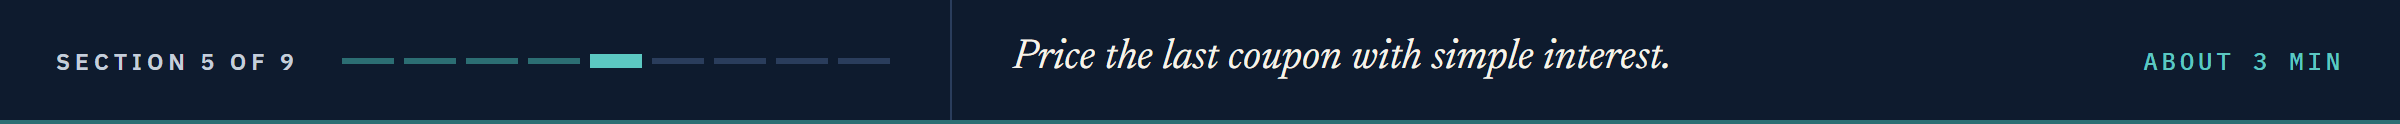

## 8.5 The Final Coupon Period

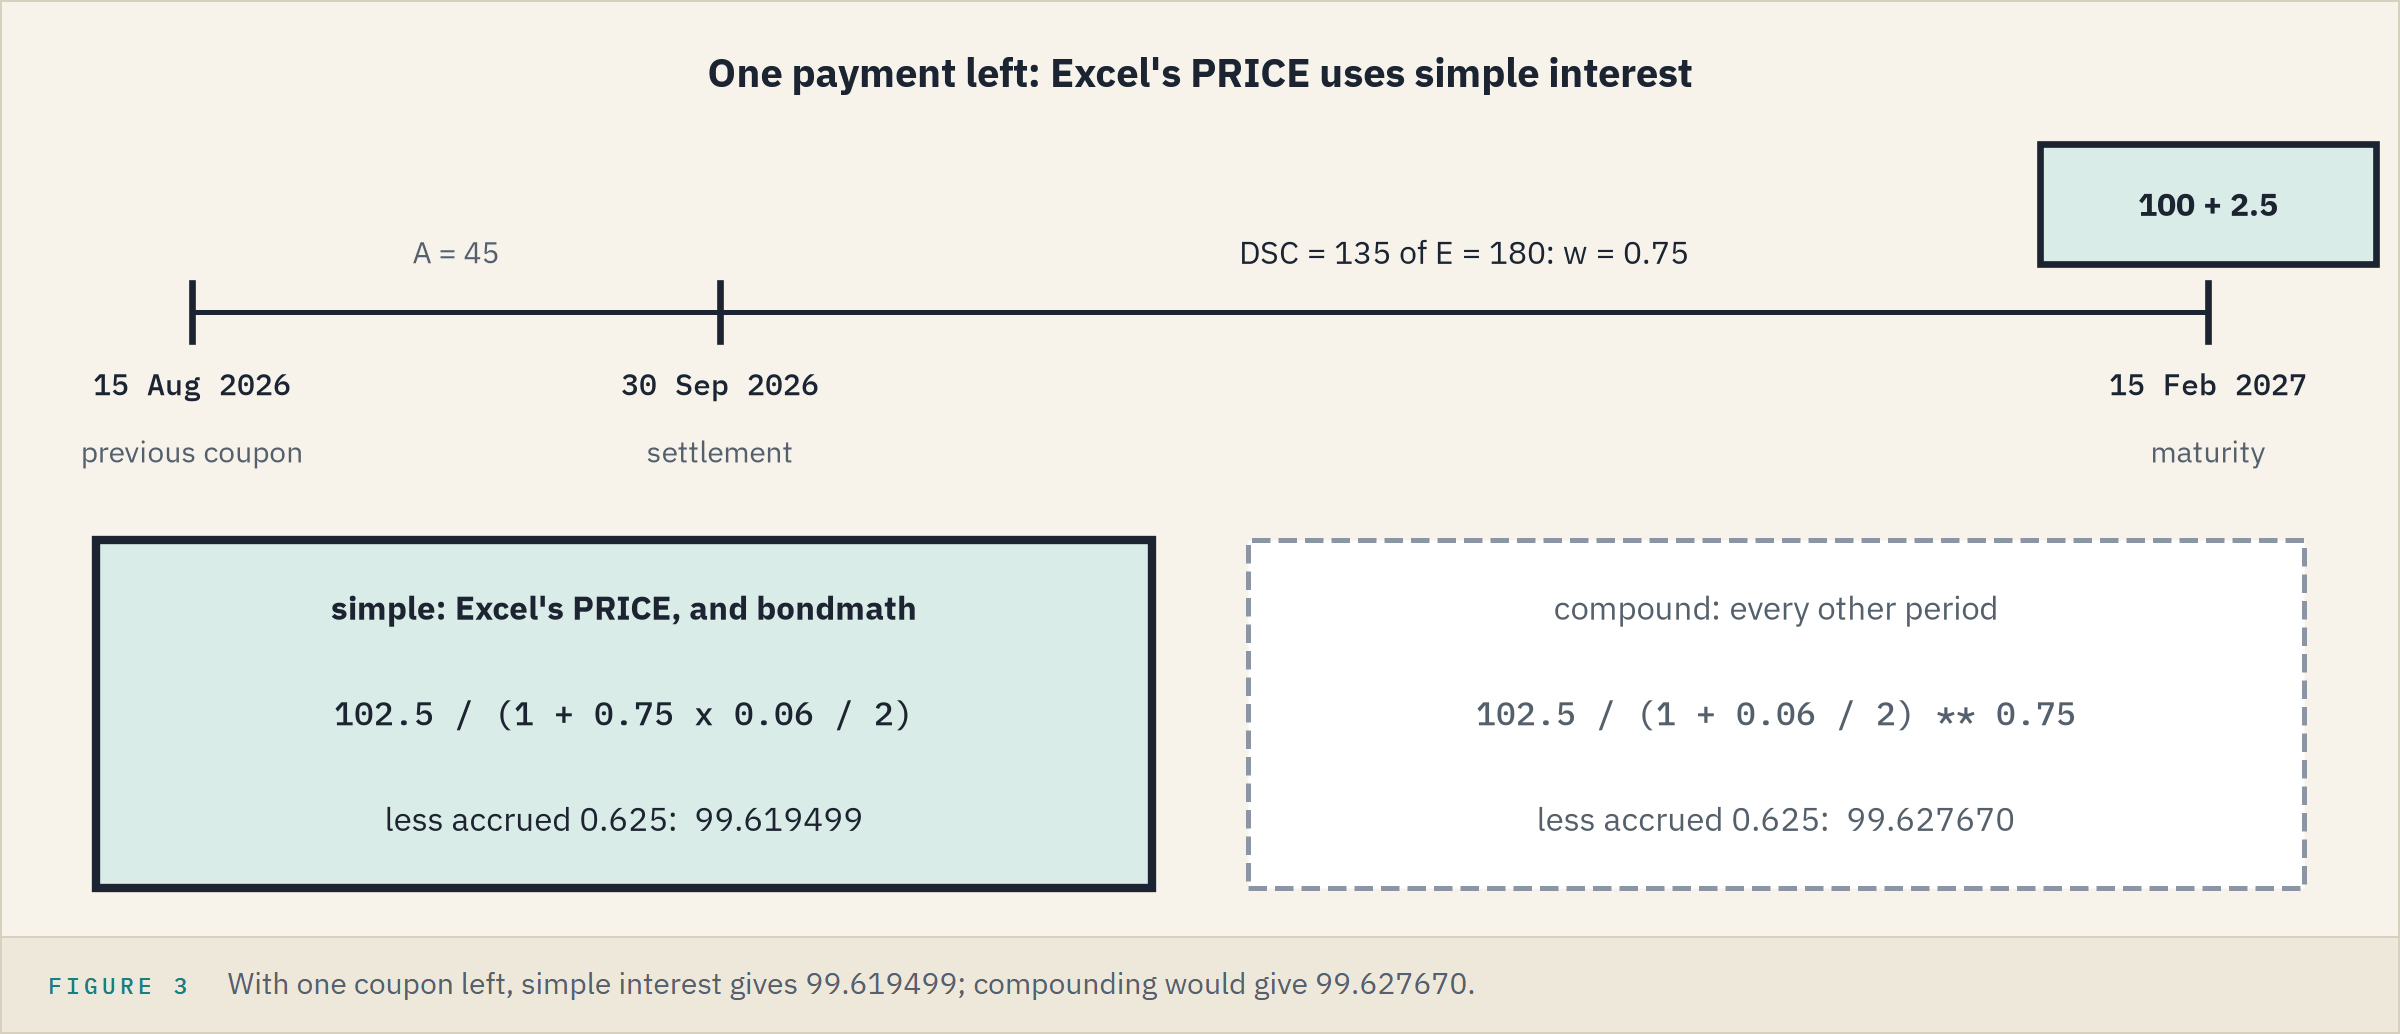

With one coupon left, Excel's `PRICE` discounts the last payment with simple interest: dirty = (100 + coupon / f) / (1 + w x y / f).
None of the four bonds is there yet, so take the reference row `edge_final_period`.

### Simple Against Compound

In [23]:
final_settlement, final_maturity = date(2026, 9, 30), date(2027, 2, 15)
a, e, dsc = bondmath.coupon_period_days(final_settlement, final_maturity)
accrued_final = bondmath.accrued_interest(final_settlement, final_maturity, 5.0)
simple = bondmath.price(final_settlement, final_maturity, 5.0, 6.0)
# the same payment compounded over dsc / e of a period, less the same accrued
compound = (100 + 5.0 / 2) / (1 + 6.0 / 100 / 2) ** (dsc / e) - accrued_final
excel_final = reference.set_index('case_id').loc['edge_final_period', 'price']
print(f"w = {dsc / e}; Excel's PRICE {excel_final:.10f}")
print(f'Simple:   {simple:.10f}')
print(f'Compound: {compound:.10f}')

w = 0.75; Excel's PRICE 99.6194987775
Simple:   99.6194987775
Compound: 99.6276697643


`price` is Excel's number to the last digit; compounding would add 0.008171 per 100, 81.71 dollars on 1,000,000.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Simple, written out</td><td align="left"><code>simple</code></td><td align="left"><code>=(100+5/2)/(1+(COUPDAYS(DATE(2026,9,30),DATE(2027,2,15),2,0)-COUPDAYBS(DATE(2026,9,30),DATE(2027,2,15),2,0))/COUPDAYS(DATE(2026,9,30),DATE(2027,2,15),2,0)*6/100/2)-100*5/100/2*COUPDAYBS(DATE(2026,9,30),DATE(2027,2,15),2,0)/COUPDAYS(DATE(2026,9,30),DATE(2027,2,15),2,0)</code></td><td align="left">99.61949877750611, as <code>PRICE</code></td></tr>
<tr><td align="left">Compound, written out</td><td align="left"><code>compound</code></td><td align="left">the same with <code>(1+6/100/2)^(...)</code> in place of <code>(1+(...)*6/100/2)</code></td><td align="left">99.62766976428897</td></tr>
</table>
<br clear="left">

### The Test

`test_price_matches_excel` covers these rows already; a test named after the convention says where a failure is.

In [24]:
%%writefile -a test_bondmath.py


def test_final_period_matches_excel():
    final_period_rows = [row for row in REFERENCE if row["coupnum"] == "1"]
    assert final_period_rows, "no final-period rows in the reference file"
    for row in final_period_rows:
        # one coupon left: Excel prices it with simple interest
        result = bondmath.price(*bond_inputs(row))
        assert result == pytest.approx(float(row["price"]), abs=1e-6), row["case_id"]

Appending to test_bondmath.py


In [25]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

......................                                                   [100%]
22 passed in 0.50s



**With one coupon left, Excel uses simple interest, and so does `bondmath`.**

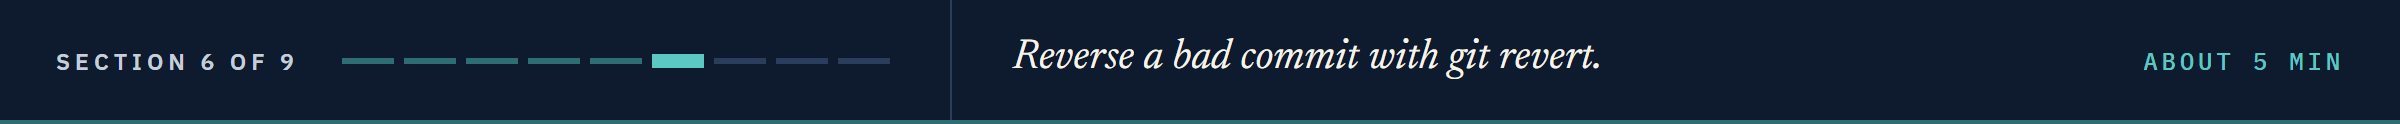

## 8.6 Undo a Commit, Keep the History

### Read the Diff, Commit the Day

In [26]:
!git -C "{work}" status --short
!git -C "{work}" diff --stat
!git -C "{work}" add bondmath.py test_bondmath.py
!git -C "{work}" commit -q -m "Add price and dirty_price, tested against Excel PRICE"
# -3: only the last three commits
!git -C "{work}" log --oneline -3

 M bondmath.py
 M test_bondmath.py
 bondmath.py      | 43 +++++++++++++++++++++++++++++++++++++++++++
 test_bondmath.py | 34 ++++++++++++++++++++++++++++++++++
 2 files changed, 77 insertions(+)
4ed07ee Add price and dirty_price, tested against Excel PRICE
98124d3 Notebook 07: days_30_360, coupon_period_days, and accrued_interest
9fe8f04 Notebook 06: add_months, coupon_dates, and a .gitignore


### A Colleague's Tidy Change

A colleague wants the final period "discounted like every other period", edits one line of `price`, and commits without running the tests.

In [27]:
# the colleague's edit: the final period compounded like every other period
with open('bondmath.py', encoding='utf-8') as file:
    text = file.read()
with open('bondmath.py', 'w', encoding='utf-8') as file:
    file.write(text.replace('(1 + w * period_yield)', '(1 + period_yield) ** w'))
!git -C "{work}" diff bondmath.py

diff --git a/bondmath.py b/bondmath.py
index c6928f7..f2bd907 100644
--- a/bondmath.py
+++ b/bondmath.py
@@ -296,7 +296,7 @@ def price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float,
     coupon = coupon_pct / frequency
     if coupons_left == 1:
         # final period: simple interest on the last coupon and the face
-        dirty = (100 + coupon) / (1 + w * period_yield)
+        dirty = (100 + coupon) / (1 + period_yield) ** w
     else:
         dirty = 0.0
         for k in range(coupons_left):


In [28]:
# -a adds every tracked file that changed, so no separate git add
!git -C "{work}" commit -q -am "Discount the final period like every other period"
!git -C "{work}" log --oneline -3

04c5b5e Discount the final period like every other period
4ed07ee Add price and dirty_price, tested against Excel PRICE
98124d3 Notebook 07: days_30_360, coupon_period_days, and accrued_interest


**Predict 3**

Q. No running bond is in its final period. Of the 22 tests:

A) none fail
B) one fails, the final-period test
C) three fail: it and the two price tests that read every row

### Run the Tests

As in notebook 07, `--tb=no` keeps pytest's output to the summary.

In [29]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', '--tb=no']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..................FF.F                                                   [100%]
=========================== short test summary info ===========================
FAILED test_bondmath.py::test_price_matches_excel - AssertionError: edge_final_period
FAILED test_bondmath.py::test_dirty_is_clean_plus_accrued - AssertionError: edge_final_period
FAILED test_bondmath.py::test_final_period_matches_excel - AssertionError: edge_final_period
3 failed, 19 passed in 0.50s



C: the two price tests loop over every reference row, final-period rows included, and `dirty_price` calls `price`.
The test named after the convention says exactly what broke.

### `git revert`

`git restore` (notebook 04) cannot help: the broken file is committed.
`git revert` makes a new commit that does the opposite of an old one.

In [30]:
# HEAD is the last commit; --no-edit keeps Git's own message for the new commit
!git -C "{work}" revert --no-edit HEAD
!git -C "{work}" log --oneline -4

[main a23e982] Revert "Discount the final period like every other period"
 Date: Wed Sep 30 09:00:00 2026 +0000
 1 file changed, 1 insertion(+), 1 deletion(-)
a23e982 Revert "Discount the final period like every other period"
04c5b5e Discount the final period like every other period
4ed07ee Add price and dirty_price, tested against Excel PRICE
98124d3 Notebook 07: days_30_360, coupon_period_days, and accrued_interest


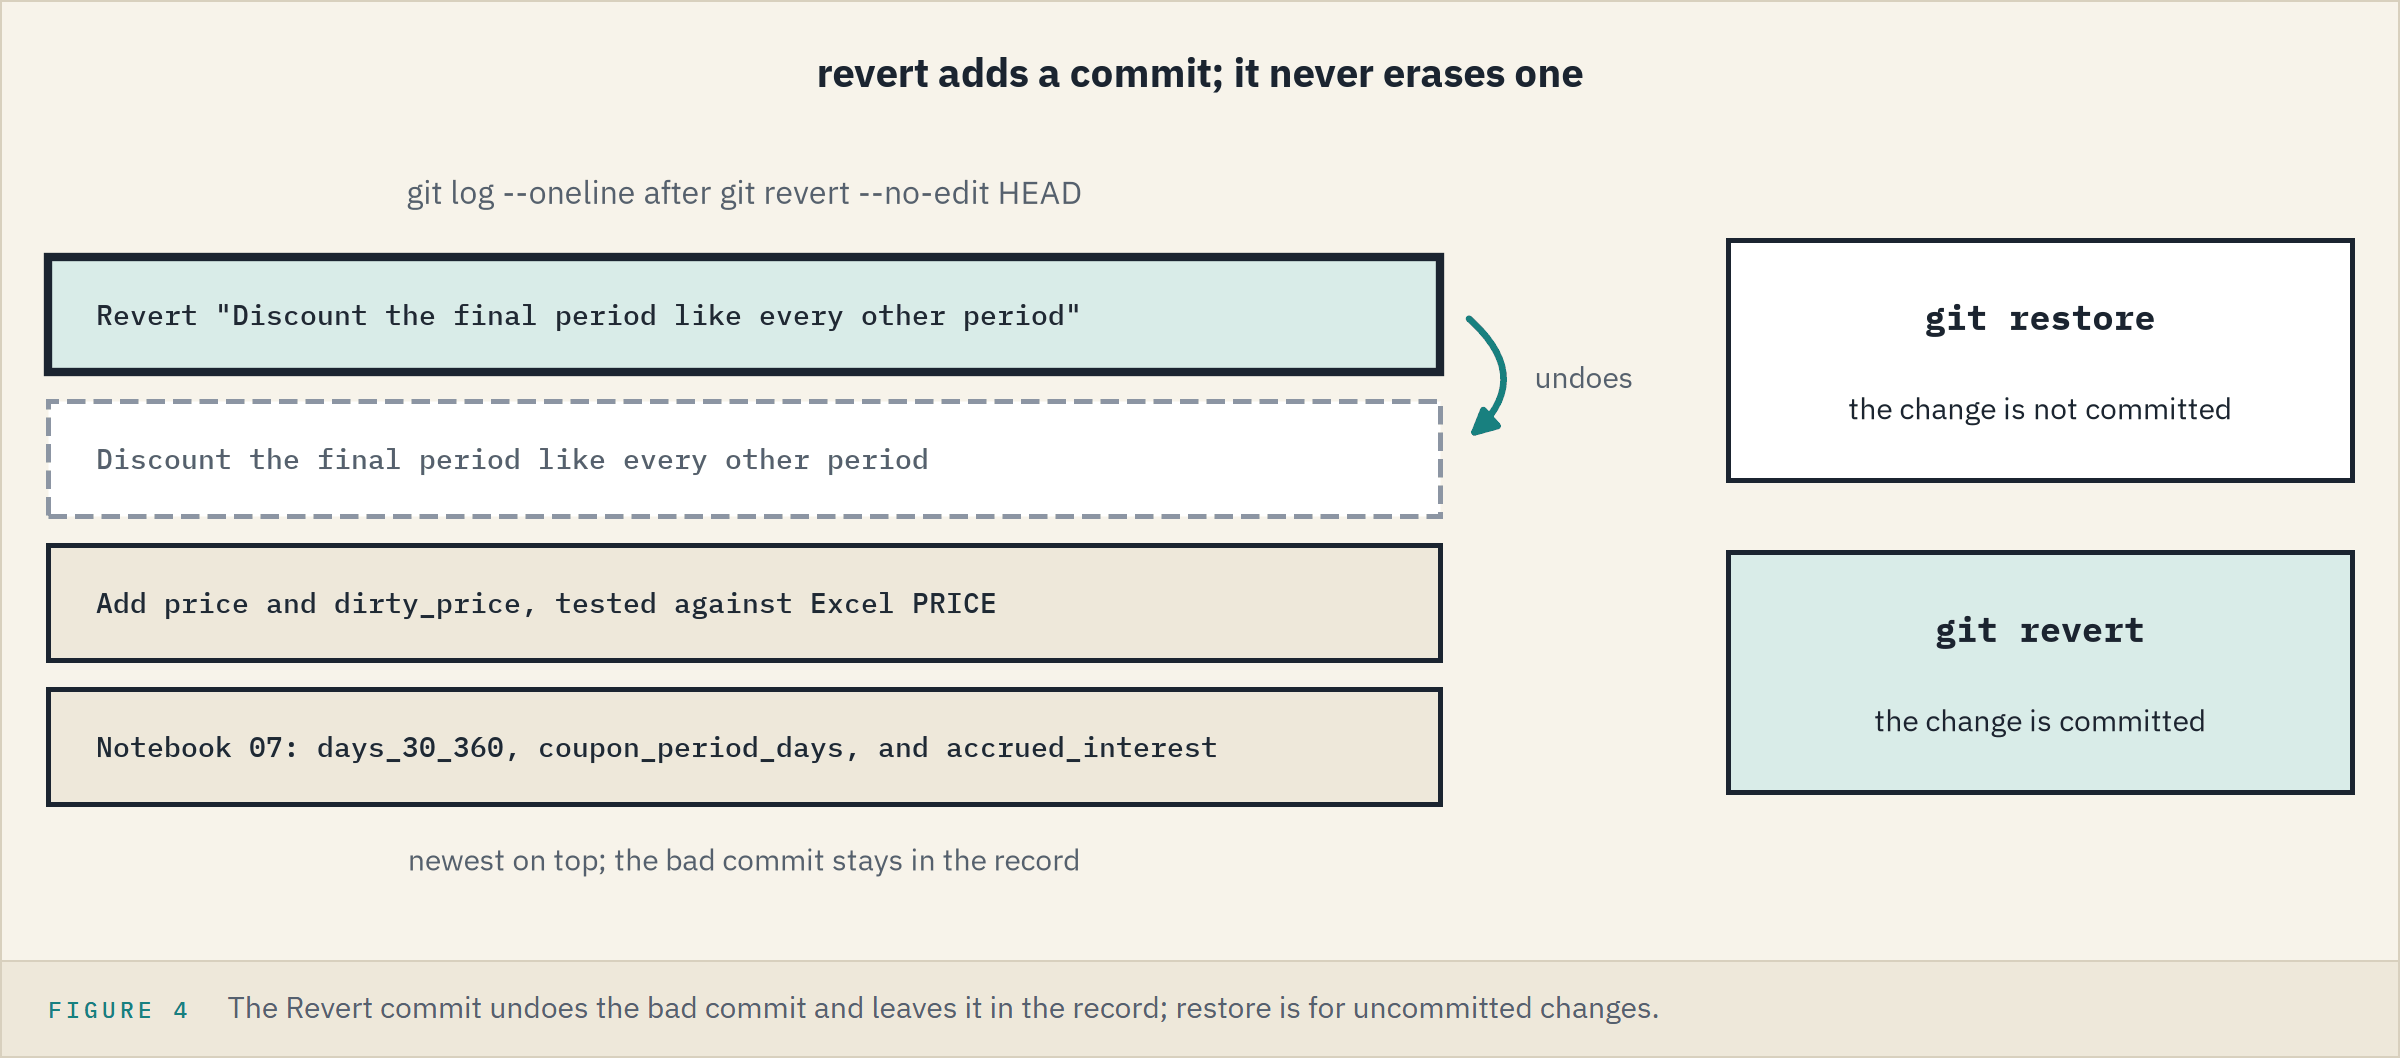

### The Tests Pass Again

In [31]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

......................                                                   [100%]
22 passed in 0.50s



**`restore` undoes what is not committed; `revert` undoes what is and keeps the record. Never rewrite a shared history; add to it.**

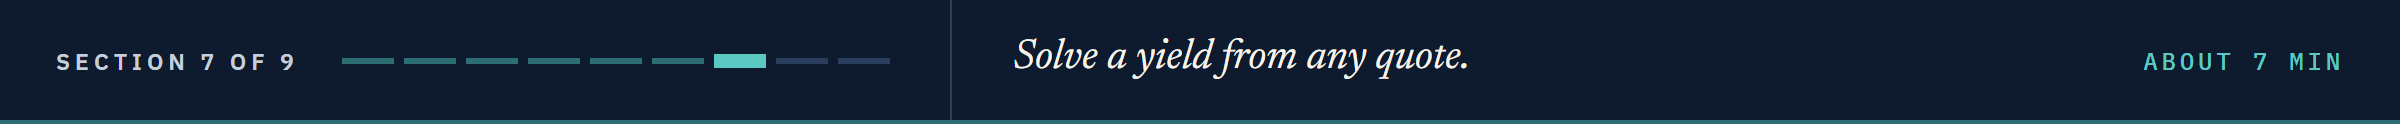

## 8.7 `yield_to_maturity`

### Append It

From a clean price back to the yield, as Excel's `YIELD`.
The docstring states the units (percent a year), the bracket (-5 to 100 percent), the final-period formula, and `YIELD`'s `*100`.
The search is notebook 04's bisection with `price` inside: ten clear lines read better than a general solver.

In [32]:
%%writefile -a bondmath.py


def yield_to_maturity(settlement: date, maturity: date, coupon_pct: float, clean_price: float,
                      frequency: int = 2, basis: str = "30/360") -> float:
    """Yield in percent from a clean price on any settlement date, by bisection, as Excel's YIELD x 100.

    Units: coupon_pct in percent a year, clean_price per 100 of face; the result is in percent a year.
    Convention: the yield at which price() equals clean_price. The search runs between -5 and 100
    percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Final coupon period: Excel's YIELD uses a formula instead of a search, with DSR, the days from
    settlement to maturity, counted by days_30_360 under 30/360 (actual days under ACT/ACT):
    yield = ((100 + CF) - dirty) / dirty x frequency x E / DSR. Under 30/360 DSR can differ from the
    E - A that PRICE uses, so in those cases YIELD does not return the yield PRICE was given.
    Excel: =YIELD(settlement, maturity, coupon_pct/100, clean_price, 100, frequency, basis)*100
    """
    # final coupon period: Excel's formula (coupon_dates and coupon_period_days check the inputs)
    if len(coupon_dates(settlement, maturity, frequency)) - 1 == 1:
        days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
        if basis == "30/360":
            days_to_maturity = days_30_360(settlement, maturity)
        else:
            days_to_maturity = (maturity - settlement).days
        coupon = coupon_pct / frequency
        # the dirty price paid, and what comes back at maturity
        paid = clean_price + coupon * days_accrued / days_in_period
        received = 100 + coupon
        # the simple return over the days left, made annual, in percent
        return (received - paid) / paid * frequency * days_in_period / days_to_maturity * 100
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price(settlement, maturity, coupon_pct, low_pct, frequency, basis)
    lowest_price = price(settlement, maturity, coupon_pct, high_pct, frequency, basis)
    if not lowest_price <= clean_price <= highest_price:
        raise ValueError(f"price {clean_price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price(settlement, maturity, coupon_pct, mid_pct, frequency, basis) > clean_price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2

Appending to bondmath.py


### The Issue Yields Come Back

In [33]:
importlib.reload(bondmath)
excel_prices = week2.loc[bonds['cusip'], 'price']
solved = [bondmath.yield_to_maturity(settlement, m, c, p)
          for m, c, p in zip(maturities, coupons, excel_prices)]
gaps = [abs(s - y) for s, y in zip(solved, yields)]
# :.1e writes a number in scientific notation: 1.9e-11 is 0.000000000019
print(f'Largest gap from the issue yields: {max(gaps):.1e} percent')

Largest gap from the issue yields: 1.9e-11 percent


**Predict 4**

Q. Notebook 04 found Quorvane's quote of 99.125 yields 5.452297 percent on 30 September. The quote holds until 30 November. Its yield:

A) stays the same
B) moves closer to the 5.25 coupon
C) moves further from it

### The Same Quotes Two Months On

In [34]:
quotes = [99.125, 100.5, 100.875, 97.75]
in_september = [bondmath.yield_to_maturity(date(2026, 9, 30), m, c, q)
                for m, c, q in zip(maturities, coupons, quotes)]
in_november = [bondmath.yield_to_maturity(settlement, m, c, q)
               for m, c, q in zip(maturities, coupons, quotes)]
change_bp = [(after - before) * 100 for before, after in zip(in_september, in_november)]
pd.DataFrame({'issuer': bonds['issuer'], 'quote': quotes, '30 Sep': in_september,
              '30 Nov': in_november, 'change_bp': change_bp}).round(6)

,issuer,quote,30 Sep,30 Nov,change_bp
0,Quorvane Energy,99.125,5.452297,5.456532,0.423586
1,Dunmarrow Rail,100.500,6.036364,6.032806,-0.355752
2,Pellwick Paper,100.875,4.435281,4.415878,-1.940314
3,Halvering Foods,97.750,7.828610,7.829977,0.136674


C: below par (Quorvane, Halvering) the yield rises; above par it falls.
The same discount or premium has two months less to pull to par, so it is worth more yield a year.
This is what the formula does with an unchanged price, not a view on any bond.

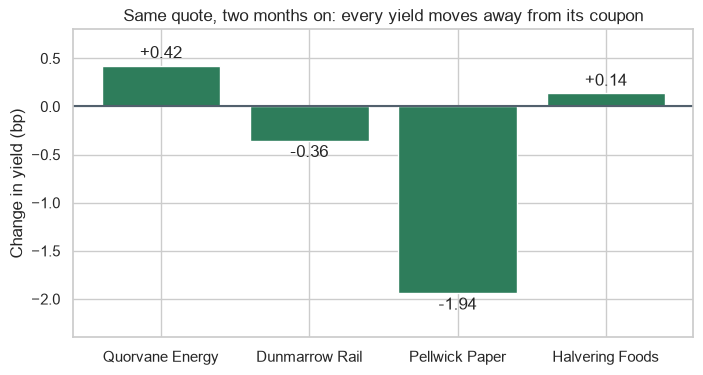

In [35]:
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(bonds['issuer'], change_bp)
ax.bar_label(bars, fmt='%+.2f', padding=3)
ax.axhline(0, color='#52606D')
ax.set_ylim(-2.4, 0.8)
ax.set_title('Same quote, two months on: every yield moves away from its coupon')
ax.set_ylabel('Change in yield (bp)')
plt.show()

### When YIELD Does Not Undo PRICE

In the final period `YIELD` uses a formula, with DSR, the days from settlement to maturity, counted on 30/360.
`PRICE` uses DSC = E - A, and near a February month end the two differ.

In [36]:
month_end = reference.set_index('case_id').loc['edge_final_period_month_end']
month_end_settlement, month_end_maturity = date(2026, 12, 15), date(2027, 2, 28)
month_end_yield = bondmath.yield_to_maturity(month_end_settlement, month_end_maturity, 6.5,
                                             month_end['price'])
repriced = bondmath.price(month_end_settlement, month_end_maturity, 6.5, month_end_yield)
print(f"PRICE at 5 percent: {month_end['price']:.6f}")
print(f"YIELD of that: {month_end['yield_pct_from_price']:.6f}; ours: {month_end_yield:.6f}")
print(f'Priced again at that yield: {repriced:.6f}')

PRICE at 5 percent: 100.289734
YIELD of that: 5.136986; ours: 5.136986
Priced again at that yield: 100.260880


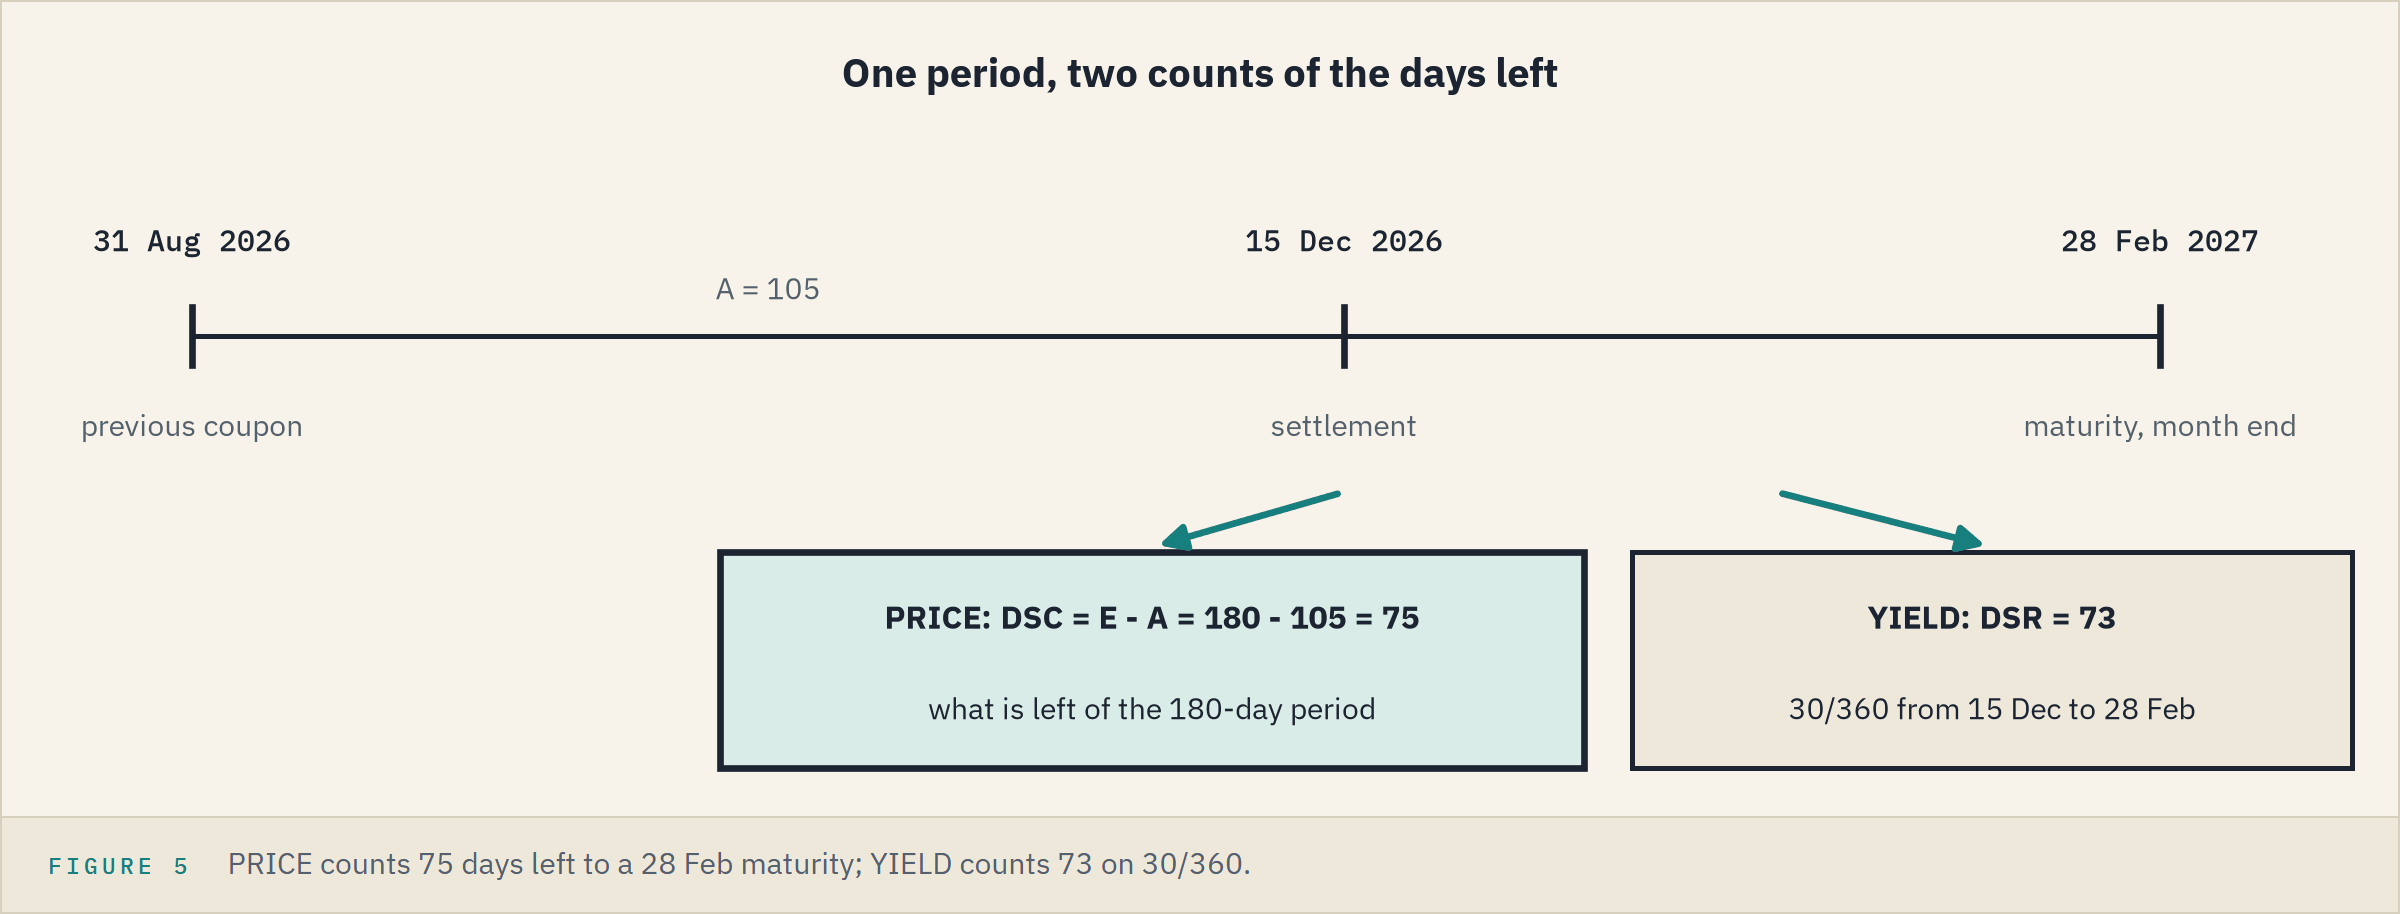

### Seventy-Five Days or Seventy-Three

In [37]:
a, e, dsc = bondmath.coupon_period_days(month_end_settlement, month_end_maturity)
print(f'E - A for PRICE: {e - a}; DSR for YIELD: '
      f'{bondmath.days_30_360(month_end_settlement, month_end_maturity)}')

E - A for PRICE: 75; DSR for YIELD: 73


Each function does what it documents, and `bondmath` follows Excel in both; no bond in the holdings file is in its final period.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Yield of a quote</td><td align="left"><code>bondmath.yield_to_maturity(settlement, quorvane_maturity, 5.25, 99.125)</code></td><td align="left"><code>=YIELD(DATE(2026,11,30),DATE(2031,9,30),5.25/100,99.125,100,2,0)*100</code></td><td align="left">5.456532360810871</td></tr>
<tr><td align="left">DSR</td><td align="left"><code>bondmath.days_30_360(...)</code></td><td align="left"><code>=YEARFRAC(DATE(2026,12,15),DATE(2027,2,28),0)*360</code></td><td align="left">73</td></tr>
<tr><td align="left">E - A</td><td align="left"><code>e - a</code></td><td align="left"><code>=COUPDAYS(DATE(2026,12,15),DATE(2027,2,28),2,0)-COUPDAYBS(DATE(2026,12,15),DATE(2027,2,28),2,0)</code></td><td align="left">75</td></tr>
</table>
<br clear="left">

### The Test, Then Commit

The test compares with `yield_pct_from_price`, Excel's `YIELD` of Excel's `PRICE`, so it holds on the month-end row too.

In [38]:
%%writefile -a test_bondmath.py


def test_yield_to_maturity_matches_excel():
    for row in REFERENCE:
        settlement, maturity, coupon_pct, _, frequency, basis = bond_inputs(row)
        # solve the yield from Excel's price, and compare with Excel's YIELD of that price
        result = bondmath.yield_to_maturity(settlement, maturity, coupon_pct, float(row["price"]), frequency, basis)
        assert result == pytest.approx(float(row["yield_pct_from_price"]), abs=1e-6), row["case_id"]

Appending to test_bondmath.py


In [39]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.......................                                                  [100%]
23 passed in 0.50s



In [40]:
!git -C "{work}" diff --stat
!git -C "{work}" commit -q -am "Add yield_to_maturity, tested against Excel YIELD"

 bondmath.py      | 47 +++++++++++++++++++++++++++++++++++++++++++++++
 test_bondmath.py |  8 ++++++++
 2 files changed, 55 insertions(+)


**From any quote to its yield, as Excel's `YIELD`, final period included.**

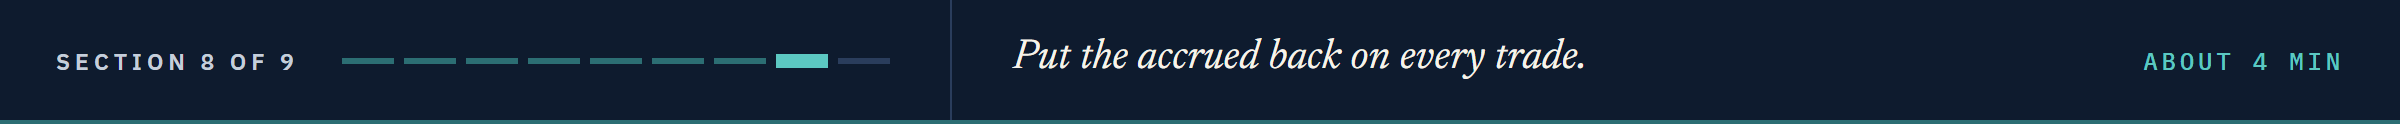

## 8.8 The September Blotter's Invoices

Course 1's Trade Blotter case study read this file.
Its `price` is the clean price and its `principal` is face times that price: no accrued.

### Read the Blotter

In [41]:
blotter = pd.read_csv('trade_blotter.csv')
print(len(blotter), 'trades, settling', blotter['settle_date'].min(), 'to',
      blotter['settle_date'].max())
blotter[['trade_id', 'settle_date', 'cusip', 'side', 'quantity', 'price', 'principal']].head(3)

374 trades, settling 2026-09-02 to 2026-10-01


,trade_id,settle_date,cusip,side,quantity,price,principal
0,T0001,2026-09-02,99087JAG1,BUY,500000,103.053,515265.00
1,T0002,2026-09-02,99003DAE0,SELL,245000,95.434,233813.30
2,T0003,2026-09-02,99051ZAA0,BUY,25000,97.875,24468.75


### Bring In Coupon and Maturity

In [42]:
holdings = pd.read_csv('holdings.csv')
# validate='many_to_one': many trades per bond, one holdings row per CUSIP
trades = blotter.merge(holdings[['cusip', 'coupon', 'maturity']], on='cusip', how='left',
                       validate='many_to_one')
assert trades['coupon'].notna().all(), 'a trade has no bond in the holdings file'
# principal is face times the clean price, to the cent
assert ((trades['quantity'] * trades['price'] / 100 - trades['principal']).abs() < 0.005).all()
print(len(trades), 'trades, each with its coupon and maturity')

374 trades, each with its coupon and maturity


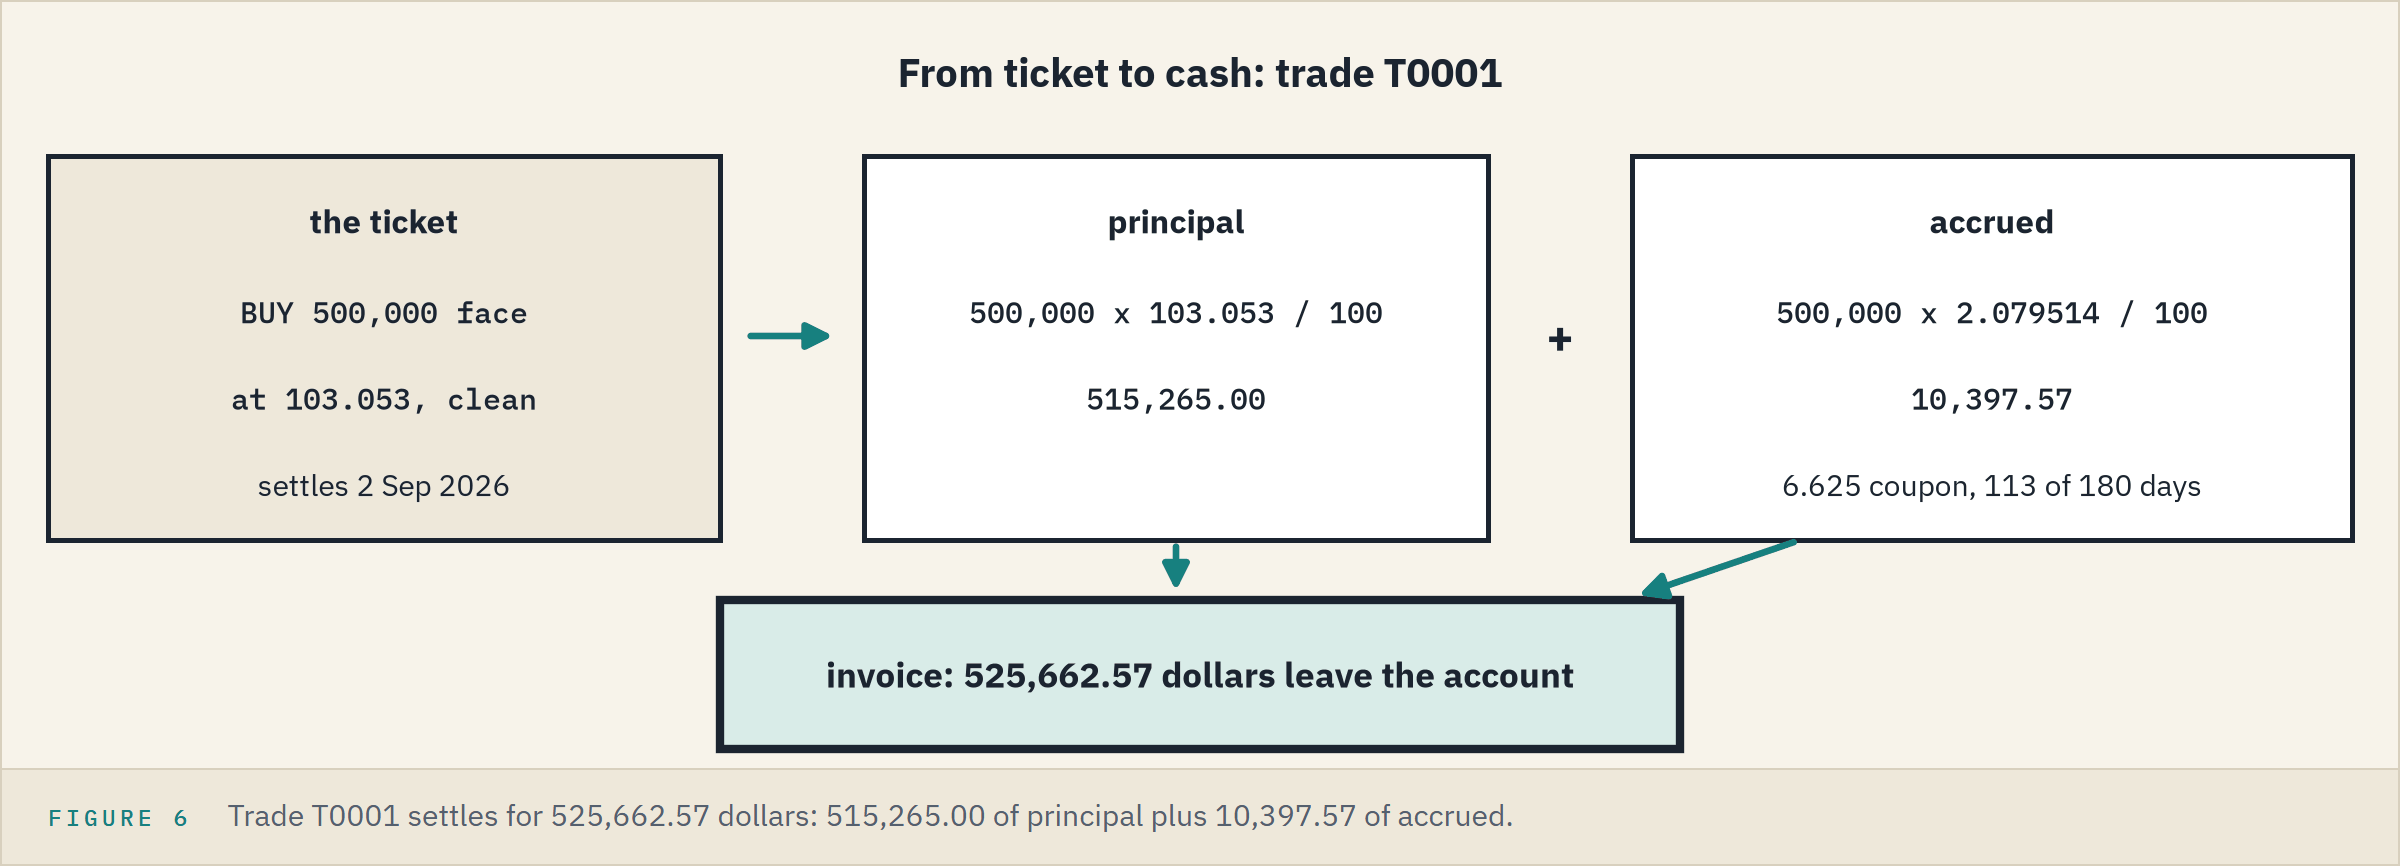

### Accrued and Invoice for Every Trade

In [43]:
# bondmath takes dates: .dt.date after pd.to_datetime, as in notebook 06
settle_dates = pd.to_datetime(trades['settle_date']).dt.date
maturity_dates = pd.to_datetime(trades['maturity']).dt.date
trades['accrued_per_100'] = [bondmath.accrued_interest(s, m, c)
                             for s, m, c in zip(settle_dates, maturity_dates, trades['coupon'])]
trades['accrued_dollars'] = trades['quantity'] * trades['accrued_per_100'] / 100
trades['invoice_dollars'] = trades['principal'] + trades['accrued_dollars']
print((trades['accrued_dollars'] == 0).sum(), 'trades accrued nothing; the most accrued:',
      trades.loc[trades['accrued_dollars'].idxmax(), 'trade_id'])
trades[['trade_id', 'quantity', 'principal', 'accrued_dollars', 'invoice_dollars']].head(3)

2 trades accrued nothing; the most accrued: T0151


,trade_id,quantity,principal,accrued_dollars,invoice_dollars
0,T0001,500000,515265.00,10397.569444,525662.569444
1,T0002,245000,233813.30,2825.156250,236638.456250
2,T0003,25000,24468.75,471.701389,24940.451389


T0001 settles for 525,662.57 dollars: 515,265.00 of principal and 10,397.57 of accrued.
The two trades that accrued nothing settled on a coupon date.

### By Side

Q. What did the month's trades really settle for, by side?

In [44]:
by_side = pd.pivot_table(trades, index='side', aggfunc='sum', margins=True,
                         values=['principal', 'accrued_dollars', 'invoice_dollars'])
by_side = by_side[['principal', 'accrued_dollars', 'invoice_dollars']]
by_side.style.format('{:,.2f}').set_caption('September trades, in dollars')

,principal,accrued_dollars,invoice_dollars
side,,,
BUY,"56,556,005.45","990,620.95","57,546,626.40"
SELL,"60,917,743.90","819,168.26","61,736,912.16"
All,"117,473,749.35","1,809,789.22","119,283,538.57"


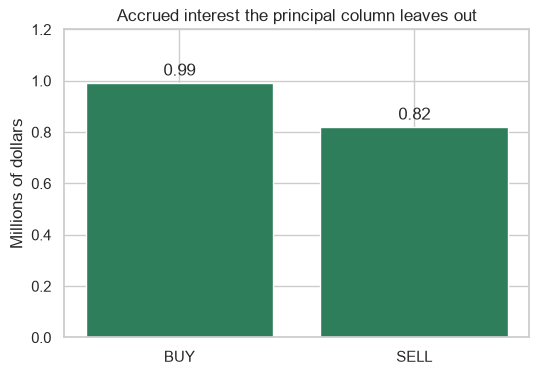

In [45]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(by_side.index[:2], by_side['accrued_dollars'].iloc[:2] / 1e6)
ax.bar_label(bars, fmt='%.2f', padding=3)
ax.set_ylim(0, 1.2)
ax.set_title('Accrued interest the principal column leaves out')
ax.set_ylabel('Millions of dollars')
plt.show()

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">T0001's invoice</td><td align="left"><code>trades['invoice_dollars']</code></td><td align="left"><code>=500000*(103.053+100*6.625/100/2*COUPDAYBS(DATE(2026,9,2),DATE(2033,5,9),2,0)/COUPDAYS(DATE(2026,9,2),DATE(2033,5,9),2,0))/100</code></td><td align="left">525662.5694444444</td></tr>
</table>
<br clear="left">

**September's trades settled for 119,283,538.57 dollars: 1,809,789.22 of accrued sits outside the principal column.**

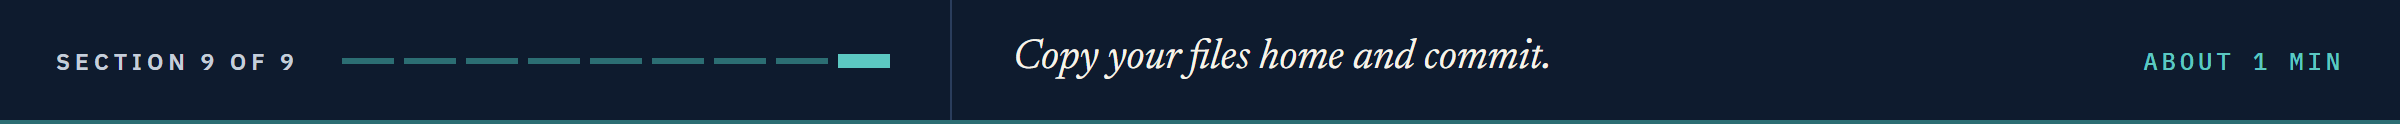

## Bring It Home

Copy the work folder's two files into your own `my_bondmath` folder, test them there, and commit.
The copy replaces your files, so anything of your own must be in the work folder first.
In a PowerShell terminal in VS Code, with the course's `.venv` active (use the folder name the setup printed):

```powershell
Set-Location "$HOME\projects\my_bondmath"
Copy-Item "$env:TEMP\pfi_course2_08_k4w7q2xr\bondmath.py", "$env:TEMP\pfi_course2_08_k4w7q2xr\test_bondmath.py" .
python -m pytest -q
git diff --stat
git commit -am "Add price, dirty_price, and yield_to_maturity, tested against Excel"
```

`Copy-Item` copies files, here into `.`, the current folder; pytest shows 23 passed.
To practise the undo, make the colleague's edit by hand, then run `git commit -am "Compound the final period"`, `python -m pytest -q --tb=no` (3 failed) and `git revert --no-edit HEAD`.
In Colab, download the two files from the work folder under `/tmp` instead.
The work folder stays in your temp folder; the system clears it in time.

## You Can Now

By the end of this notebook, you can:

* Tell the quote from the invoice, and price the invoice in dollars.
* Discount from settlement over w + k periods, in Python and in a sheet.
* Price any settlement date with `price` and `dirty_price`, tied to Excel's `PRICE`.
* Show that a new function keeps the old answers on a coupon date.
* Price the final coupon period with simple interest, as Excel does.
* Solve a yield with `yield_to_maturity`, tied to `YIELD`, and say when `YIELD` does not undo `PRICE`.
* Undo a committed change with `git revert`.
* Put the accrued back on every trade of a blotter.

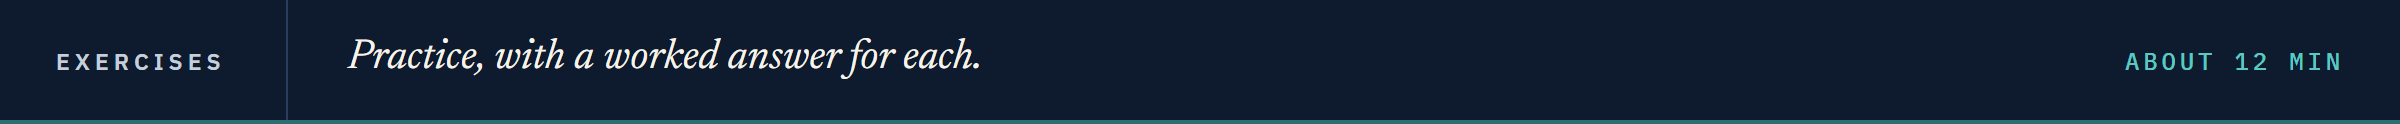

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The second set of four bonds and three trades in them, all 30/360 and semiannual.
Replace each `...` with your own code, then run the check cell under it.
Run the next two cells first: `check`, and the bonds and trades.

In [46]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [47]:
exercise_bonds = pd.DataFrame({
    'ticker': ['OSTV', 'TRNW', 'OSMC', 'CLDB'],
    'coupon_pct': [5.625, 4.375, 5.0, 8.25],
    'maturity': [date(2030, 9, 30), date(2028, 9, 30), date(2032, 9, 30), date(2034, 9, 30)],
    'yield_pct': [5.8, 4.3, 5.35, 8.6],
})
# three trades: settlement, face in dollars, and the quoted clean price
exercise_trades = pd.DataFrame({
    'ticker': ['OSTV', 'OSMC', 'CLDB'],
    'settlement': [date(2027, 1, 15), date(2026, 12, 31), date(2027, 2, 26)],
    'face_dollars': [2_000_000, 1_500_000, 750_000],
    'clean_price': [99.40, 98.30, 98.10],
}).merge(exercise_bonds[['ticker', 'coupon_pct', 'maturity']], on='ticker')
exercise_trades

,ticker,settlement,face_dollars,clean_price,coupon_pct,maturity
0,OSTV,2027-01-15,2000000,99.4,5.625,2030-09-30
1,OSMC,2026-12-31,1500000,98.3,5.000,2032-09-30
2,CLDB,2027-02-26,750000,98.1,8.250,2034-09-30


### Exercise 1

Q. Price the four bonds on 30 November 2026 at their yields. Store Calderby's (`CLDB`) clean price in **ex1_calderby_clean** and Tarnwick's (`TRNW`) dirty price in **ex1_tarnwick_dirty**.

In [48]:
ex1_calderby_clean = ...
ex1_tarnwick_dirty = ...

In [49]:
check('Exercise 1 Calderby clean price', ex1_calderby_clean, 98.0153196112818)
check('Exercise 1 Tarnwick dirty price', ex1_tarnwick_dirty, 100.8548750077241)

Exercise 1 Calderby clean price: not attempted yet
Exercise 1 Tarnwick dirty price: not attempted yet


### Exercise 2

Q. For each trade, find the accrued per 100, the yield of its quote, and the invoice in dollars. Store Osmere's (`OSMC`) accrued in **ex2_osmere_accrued**, Calderby's yield in **ex2_calderby_yield**, and the three invoices' total in **ex2_total_invoice**.

In [50]:
ex2_osmere_accrued = ...
ex2_calderby_yield = ...
ex2_total_invoice = ...

In [51]:
check('Exercise 2 Osmere accrued', ex2_osmere_accrued, 1.25)
check('Exercise 2 Calderby yield', ex2_calderby_yield, 8.593362577678363)
check('Exercise 2 total invoice', ex2_total_invoice, 4274906.25)

Exercise 2 Osmere accrued: not attempted yet
Exercise 2 Calderby yield: not attempted yet
Exercise 2 total invoice: not attempted yet


### Exercise 3

Q. Add `invoice_amount_dollars(par, clean_price, accrued_per_100)` to the module, docstring first, and `test_invoice_amount_dollars_hand_cases` with two cases worked by hand: 1,000,000 at 99.5 with 0.875 accrued, and 500,000 at 101.25 on a coupon date. Run pytest, reload, and store the Ostrevale trade's invoice in **ex3_ostrevale**.

In [52]:
%%writefile -a bondmath.py


# Exercise 3: write invoice_amount_dollars(par, clean_price, accrued_per_100) below this line

Appending to bondmath.py


In [53]:
%%writefile -a test_bondmath.py


# Exercise 3: write test_invoice_amount_dollars_hand_cases() below this line

Appending to test_bondmath.py


In [54]:
# run pytest as in the lesson, reload the module, then call your function
ex3_ostrevale = ...

In [55]:
check('Exercise 3 Ostrevale invoice', ex3_ostrevale, 2020812.5)

Exercise 3 Ostrevale invoice: not attempted yet


### Exercise 4: AI check

You gave an assistant the docstring of `price` (8.3) as the prompt.
The function below came back, written for this course in the style of an assistant's answer; it runs, and holds one bug.

In [56]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
def assistant_price(settlement, maturity, coupon_pct, yield_pct, frequency=2, basis='30/360'):
    """Clean price per 100 of face on any settlement date, as Excel's PRICE."""
    dates = bondmath.coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = bondmath.coupon_period_days(settlement, maturity,
                                                                  frequency, basis)
    n, y, cf = len(dates) - 1, yield_pct / 100 / frequency, coupon_pct / frequency
    w = days_to_next / days_in_period
    if n == 1:
        # one coupon left: simple interest, as Excel does
        return (100 + cf) / (1 + w * y)
    return sum([(cf + (100 if k == n - 1 else 0)) / (1 + y) ** (w + k) for k in range(n)])

Q. Test it on every reference row before you trust it.

In [57]:
# the test file's reference rows and bond_inputs (notebook 07), read as the tests read them
from test_bondmath import REFERENCE, bond_inputs
for row in REFERENCE:
    result = assistant_price(*bond_inputs(row))
    # Excel's PRICE is the clean price, per 100 of face
    excel_price = float(row['price'])
    message = f"{row['case_id']}: {result:.6f}, PRICE {excel_price:.6f}"
    assert abs(result - excel_price) < 1e-6, message
print("Every row matches Excel's PRICE")

AssertionError: 99080CAE8: 108.709928, PRICE 106.726595

Q. Read the message, find the convention the code broke, and fix the function until the test passes. Store the fixed function's price for Quorvane on 30 November at 5.40 percent in **ex4_quorvane**, and for Calderby (8.25 percent, 30 September 2034, at 8.60) in **ex4_calderby**.

In [58]:
ex4_quorvane = ...
ex4_calderby = ...

In [59]:
check('Exercise 4 Quorvane clean price', ex4_quorvane, 99.36155142589136)
check('Exercise 4 Calderby clean price', ex4_calderby, 98.0153196112818)

Exercise 4 Quorvane clean price: not attempted yet
Exercise 4 Calderby clean price: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">The quote</td><td align="left">99.361551 per 100</td></tr>
<tr><td align="left">The cash</td><td align="left">1,002,365.51 dollars</td></tr>
<tr><td align="left">A price for any date</td><td align="left"><code>price</code> and <code>dirty_price</code>, all 306 rows of <code>PRICE</code></td></tr>
<tr><td align="left">A yield from any quote</td><td align="left"><code>yield_to_maturity</code>, all 306 rows of <code>YIELD</code></td></tr>
<tr><td align="left">September's cash</td><td align="left">119,283,538.57 dollars, 1,809,789.22 of it accrued</td></tr>
</table>
<br clear="left">

Be proud: you priced a bond on any day of its life, tied it to Excel on every reference row, and undid a committed mistake without losing its record.

Next: Duration and DV01 (notebook 09) asks how far that price moves for a basis point.

[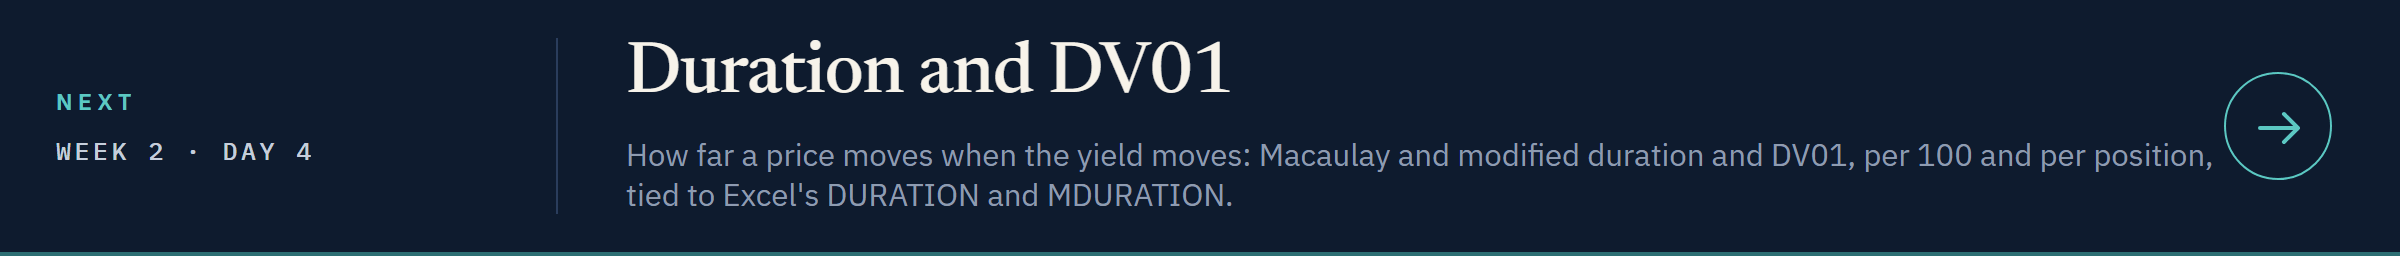](../day4/09_duration_and_dv01.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week2/day4/09_duration_and_dv01.ipynb)